# E112 · How many children in your county are poor? Small-area estimates for 3,142 counties, and a map of surprise instead of noise

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real, all US federal works in the public domain (17 U.S.C. 105), retrieved 2026-11-06: the Census Bureau's American Community Survey 5-year estimates of children in poverty, table B17020, for **two non-overlapping samples** (2019-2023 and 2014-2018) of every county; the Census Bureau's SAIPE 2023 county estimates (used only as an outside check); the USDA ERS Rural-Urban Continuum Codes 2023. Built into one 357 KB table by `tools/build_e112_saipe.py`. County outlines: Census cartographic boundaries as redistributed in `plotly/datasets` (the repository's `us_counties_geojson`) |
| **You will learn** | The **Fay-Herriot** area-level model: a survey estimate with a known margin of error, blended with a regression guess by how much each can be trusted · the shrinkage weight as a picture · prior and mixed predictive checks for a model with one observation per area · **generalised variance functions** (Wolter) tied to the true rate (Liu, Lahiri & Kalton), with published variances as data (after You & Chapman) · zero estimates as censored observations, and a split likelihood that keeps them cheap · what a margin of error does *not* tell you, measured with a second, independent survey · two failures with clean diagnostics: a model that believes a survey's zero, and **heavy-tailed survey errors** that explain away the poorest counties · replication as the fix · validation against an administrative-records model · rank uncertainty · for the public: a **Bayesian surprise map** (Correll & Heer) beside a **value-suppressing** estimate map, "find your county" dotplot cards, a shrinkage beeswarm, and the pitfall of a surprise threshold |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: one BLAS pool per chain would fight

import json
import logging
import sys
import textwrap
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import xarray as xr
from IPython.display import Markdown, display
from matplotlib.collections import EllipseCollection, LineCollection, PolyCollection
from matplotlib.colors import TwoSlopeNorm, to_rgb
from scipy.special import expit, gammaln, logit, logsumexp
from scipy.stats import norm
from scipy.stats import t as tdist

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 112
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
warnings.filterwarnings("ignore", message="There are no gridspecs with layoutgrids")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()
TIMES = {}
INK, MUTED, LIGHT, HI, LO = pub.INK, pub.MUTED, pub.LIGHT, pub.HI, pub.LO
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, nutpie {nutpie.__version__}")

PyMC 6.3.2, ArviZ 1.3.0, nutpie 0.16.11


## In plain words

**The question.** The survey says a third of the children in my small county are poor, give or
take ten points. Is that real, and where is child poverty *surprisingly* high?

**What we did.** Almost every county has two independent Census surveys. We blended them with a
guess from similar counties, trusting each survey as far as its size deserves, and looked for
counties far from the national rate, the state's rate and that of similar counties.

**What we found.** Often not quite: a small county's single survey is easily several points off. Unless both surveys agree, the model pulls it towards similar counties, by about 4 points in the smallest fifth of counties. Seven counties stand out as surprisingly poor, all on Dakota reservations or tribal land (Pine Ridge and Rosebud among them): surveys there find 29-64% of children poor, against 10-14% expected. One, Los Alamos, NM, is surprisingly low. How many stand out depends on settings; who leads does much less.

**How sure are we.** Mason County, Texas, whose latest survey found no poor children, comes out at 18% (13%-25%). It is *very likely* (98%) that more than one child in ten there is poor. We have *medium confidence* in that figure: our outside check, the Census Bureau's estimates, shares part of our data and runs about 3 points higher in small counties.

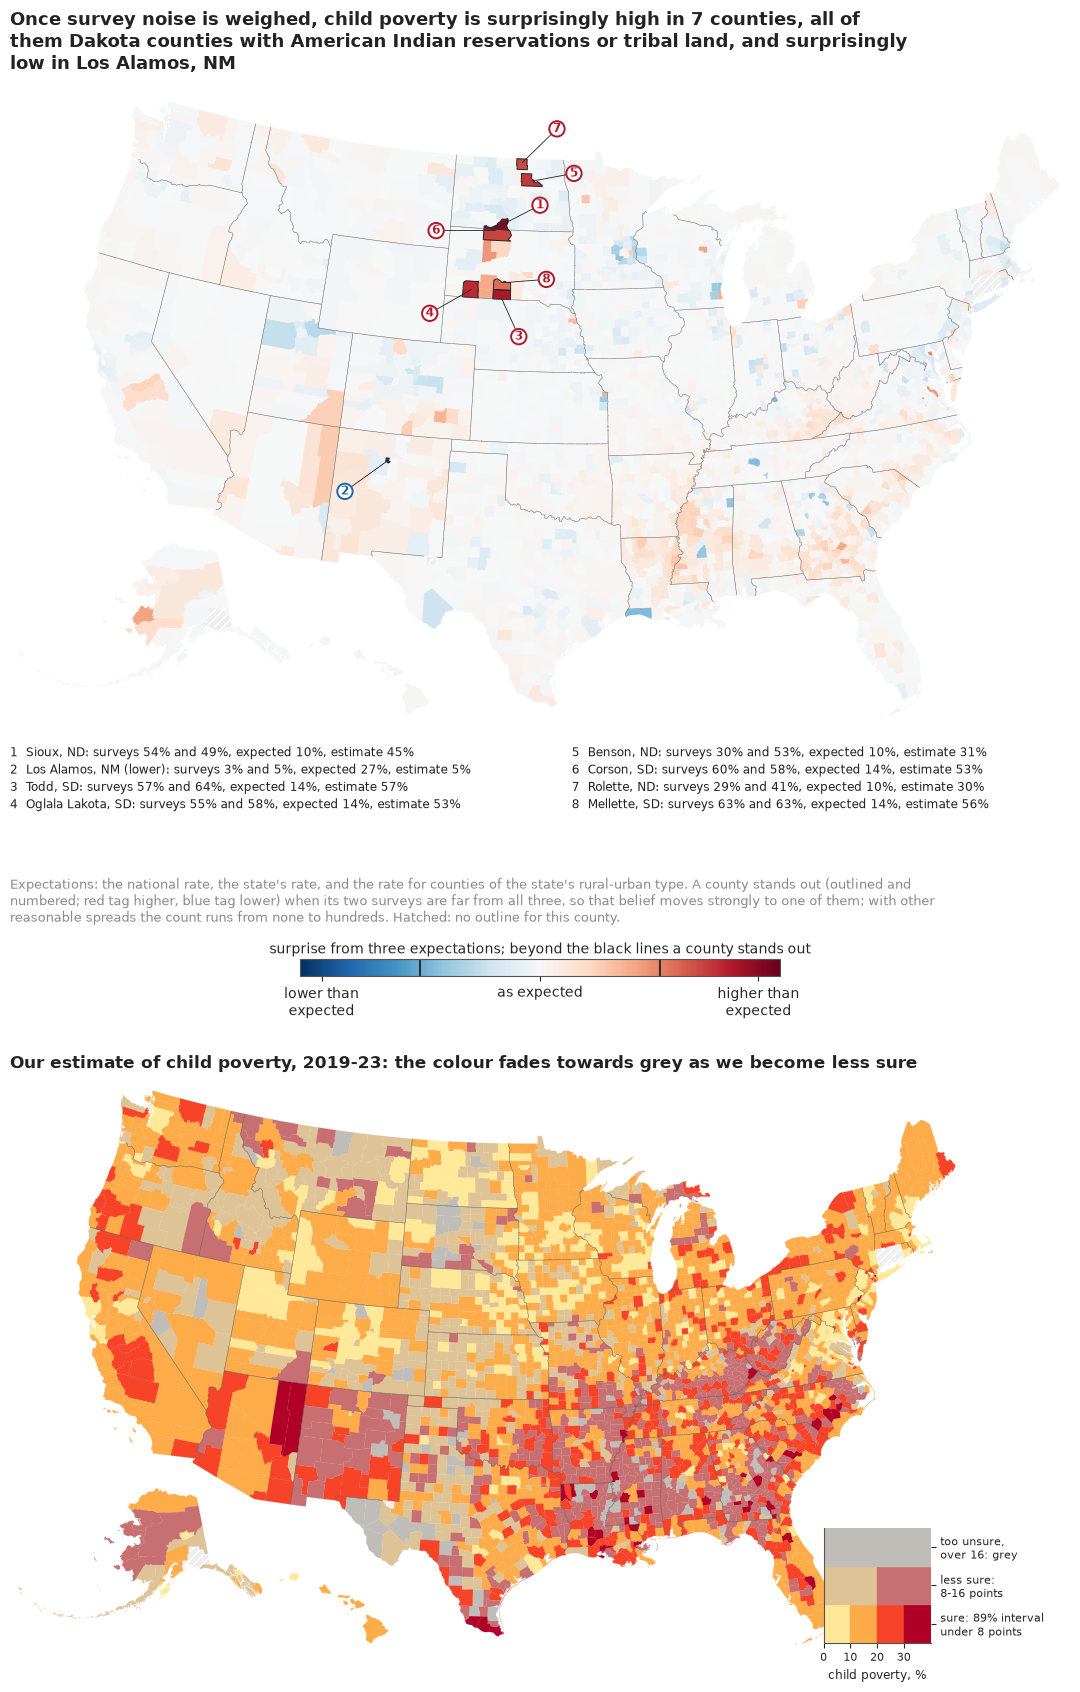

In [2]:
PLAIN = display(Markdown("**What we found.** *Filled in from the fits in part H.*\n\n"
                         "**How sure are we.** *Filled in from the fits in part H.*"),
                display_id=True)
HEADLINE = display(Markdown("*The headline figure is drawn in part H from the fits below and "
                            "appears here once the notebook has run.*"), display_id=True)

## The setting

Every year the US government publishes a child poverty rate for each of its 3,144 counties and
county equivalents. Those numbers decide real money: Title I school funding is allocated from
them. The American Community Survey (ACS) samples about 3.5 million addresses a year, which sounds
like a lot, until it is divided among counties. A ranching county with 900 children is reached
in a few dozen households even over five years of the survey, and its estimate comes with a
margin of error of ten points or more. Some of those estimates are exactly zero.

The standard answer is the model of **Fay & Herriot (1979)**, written to estimate income in small
places: treat the survey estimate as a noisy measurement of a county's true rate, with the
survey's own variance, and give the true rate a regression prior from what the county has in
common with others. The posterior leans on the survey where it is precise and on the regression
where it is not. It
is the engine of the Census Bureau's Small Area Income and Poverty Estimates (SAIPE; Bell, Basel &
Maples 2016), which add tax and food assistance records as covariates; Rao & Molina (2015) is the
textbook. Its weak point is that the survey variances are estimated from the same small samples;
You & Chapman (2006) put them into the model as data.

The same problem breaks maps. A choropleth of raw rates gives its most extreme colours to the
smallest places, because they are the noisiest: "all maps of parameter estimates are misleading"
(Gelman & Price 1999). Correll & Heer (2017) proposed to colour each place by how much its data
**surprise** a small set of reasonable expectations, a Bayesian quantity, and Correll, Moritz &
Heer (2018) to let colour fade to grey where an estimate is uncertain. We build both.

We fit 3,142 counties in four steps, and two of the steps fail in instructive ways. What rescues
the model is not a cleverer prior but a second, independent survey of nearly every county; with
one survey, even heavy tails on both the survey errors and the county effects do not help.

| part | question | tool |
|---|---|---|
| A | What do 3,142 county surveys look like? | margins, a funnel plot, the extremes |
| B | What does Fay-Herriot do? | 50 simulated counties and the shrinkage weight |
| C | Does the classic model work on real counties? | logit Fay-Herriot, prior and mixed checks |
| D | What does a margin of error not tell you? | two surveys of the same counties; two failures |
| E | Can two surveys tell a fluke from a fact? | the two-survey model with heavy-tailed errors |
| F | Do we agree with the Census Bureau? | SAIPE as an outside check |
| G | Which counties are poorest, honestly? | rank probabilities |
| H | How do we explain it to everyone? | a surprise map, a VSUP map, county cards, a beeswarm |

## A · 3,142 surveys of children in poverty

The table holds one row per county from ACS table B17020: children under 18 whose poverty status
was determined, how many of them were below the poverty line, and the 90% margins of error of
both, for 2019-2023 and for the earlier, non-overlapping 2014-2018 sample. The build script sums
three age cells (under 6, 6-11, 12-17) and combines their margins in quadrature, the ACS
handbook's approximation for a sum, then turns the count into a proportion with its standard error
(SE = MOE / 1.645). Table B17001 has the same counts but needs twelve cells, and each cell added
in quadrature understates the margin a little more (by a median 10% here). Loving County, Texas,
and Kalawao County, Hawaii, have no children with a poverty status and are dropped.

In [3]:
data.describe("e112_county_child_poverty")
RAW = data.load("e112_county_child_poverty")
D = RAW[RAW["n_children"] > 0].reset_index(drop=True)
D["short"] = D["county"].str.replace(
    r" (County|Parish|Borough|Census Area|Municipality|City and Borough|Planning Region)$", "",
    regex=True) + ", " + D["state"]
n_cty = len(D)
N = D["n_children"].to_numpy(float)
X = D["n_poor"].to_numpy(float)
P = D["p_acs"].to_numpy()
SE = D["se_acs"].to_numpy()
OK18 = D["n_children_18"].fillna(0).to_numpy() > 0
N18 = np.where(OK18, D["n_children_18"].fillna(1).to_numpy(float), 1.0)
X18 = np.where(OK18, D["n_poor_18"].fillna(0).to_numpy(float), 0.0)
P18 = np.where(OK18, D["p_acs_18"].fillna(0).to_numpy(), 0.0)
SE18 = D["se_acs_18"].fillna(1).to_numpy()
SAIPE = D["saipe_pct"].to_numpy() / 100
SAIPE_SE = (D["saipe_hi"] - D["saipe_lo"]).to_numpy() / 200 / 1.645
Q = pd.qcut(N, 5, labels=False)  # size fifths, 0 = smallest
NAT = X.sum() / N.sum()
NAT18 = X18[OK18].sum() / N18[OK18].sum()
ZERO = X == 0
IDX = {f: i for i, f in enumerate(D["fips"])}
print(f"{n_cty:,} counties; {OK18.sum():,} also in the 2014-18 survey; {ZERO.sum()} with an "
      f"estimate of exactly 0")
print(f"children per county: median {np.median(N):,.0f}, 1% {np.quantile(N, 0.01):,.0f}, "
      f"5% {np.quantile(N, 0.05):,.0f}, largest {N.max():,.0f}")
print(f"national child poverty: 2019-23 {NAT:.1%}, 2014-18 {NAT18:.1%}")
print("standard error of the survey estimate (points), median by size fifth:",
      [round(float(np.median(SE[Q == k]) * 100), 1) for k in range(5)])
print(D.loc[ZERO, ["short", "n_children", "se_acs", "p_acs_18", "saipe_pct"]]
      .assign(se_acs=lambda t: (100 * t.se_acs).round(1),
              p_acs_18=lambda t: (100 * t.p_acs_18).round(1))
      .rename(columns={"se_acs": "se (pts)", "p_acs_18": "2014-18 %", "saipe_pct": "SAIPE %"})
      .to_string(index=False))

e112_county_child_poverty: One row per county or county equivalent, 50 states + DC (3,144 rows; Connecticut as its nine planning regions): fips, state, county, n_children (children under 18 with poverty status determined, ACS 2019-23), n_poor (of them below poverty), moe_poor, moe_children (90% margins of the sums: root sum of squares over the under-6, 6-11 and 12-17 cells), p_acs, se_acs (direct proportion and its standard error, ACS proportion formula, SE = MOE / 1.645), rucc (1-9), pop2020, saipe_pct, saipe_lo, saipe_hi (SAIPE 2023 model-based under-18 poverty % and 90% bounds; Kalawao HI missing), n_children_18, n_poor_18, p_acs_18, se_acs_18 (the same from the non-overlapping ACS 2014-18 sample; missing for the CT planning regions and AK 02063/02066). Loving TX and Kalawao HI have no children with poverty status; 14 counties have a direct estimate of exactly 0.
  source: US Census Bureau American Community Survey 5-year estimates, table B17020 (poverty status by age), 2019-2023 (t

The median county has about 5,500 children, but one in twenty has fewer than about 570, and the
survey's standard error is about four points in the smallest fifth against about one point in the
largest. Fourteen counties report no poor children at all. The table above already holds the hint
that drives this notebook: every one of those zeros came from a county whose earlier survey found
poor children, often many, 23% in Mason County and 37% in Crockett County, Texas, and whose SAIPE
estimate, built from tax and benefit records, is 10-28%.

A **funnel plot** shows the size problem in one picture: survey estimate against the number of
children, with the band a survey of that size would produce around the national rate if every
county were the same. The band uses the survey's typical design effect (computed below), the
factor by which its variance exceeds that of a simple random sample of the county's children.

typical design effect relative to the county's children: 27


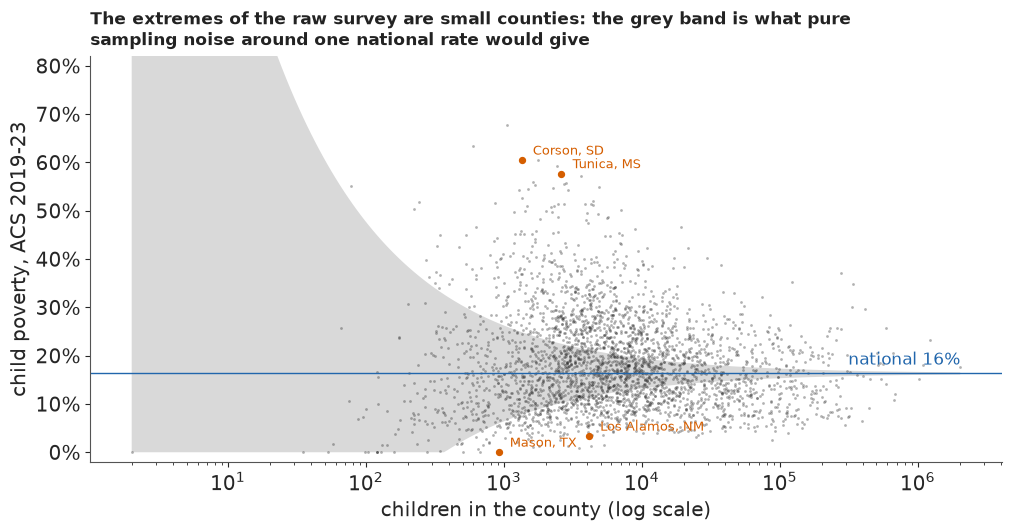

In [4]:
HAS = (X > 0) & (X < N)
DEFF = np.median(SE[HAS] ** 2 * N[HAS] / (P[HAS] * (1 - P[HAS])))
print(f"typical design effect relative to the county's children: {DEFF:.0f}")


def funnel(ax, est, title, label_these=()):
    ng = np.geomspace(N.min(), N.max(), 200)
    band = 1.645 * np.sqrt(DEFF * NAT * (1 - NAT) / ng)
    ax.fill_between(ng, np.clip(NAT - band, 0, 1), NAT + band, color=LIGHT, lw=0, zorder=0)
    ax.scatter(N, est, s=4, color=INK, alpha=0.35, lw=0)
    ax.axhline(NAT, color=HI, lw=1)
    ax.text(N.max(), NAT + 0.01, f"national {NAT:.0%}", ha="right", va="bottom", color=HI)
    for f in label_these:
        i = IDX[f]
        ax.annotate(D["short"][i], (N[i], est[i]), xytext=(8, 4), textcoords="offset points",
                    fontsize=9, color=LO)
        ax.scatter([N[i]], [est[i]], s=18, color=LO, zorder=3)
    ax.set(xscale="log", xlabel="children in the county (log scale)", ylim=(-0.02, 0.82))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    pub._title(ax, title)


fig, ax = plt.subplots(figsize=(10, 5.2))
funnel(ax, P, "The extremes of the raw survey are small counties: the grey band is what pure "
       "sampling noise around one national rate would give", ("48319", "46031", "28143", "35028"))
ax.set_ylabel("child poverty, ACS 2019-23");

In [5]:
def size_of_extremes(est):
    o = np.argsort(est)
    lo50, hi50 = o[:50], o[-50:]
    return (int((Q[lo50] == 0).sum()), int(np.median(N[lo50])), int((Q[hi50] == 0).sum()),
            int(np.median(N[hi50])))


GP_RAW = size_of_extremes(P)
print("raw survey: of the 50 lowest rates, %d are in the smallest fifth (median %d children); "
      "of the 50 highest, %d (median %d)" % GP_RAW)

raw survey: of the 50 lowest rates, 38 are in the smallest fifth (median 687 children); of the 50 highest, 20 (median 2355)


Of the 50 lowest survey rates, 38 come from the smallest fifth of counties (median about 690
children), where 10 would if size did not matter: a map of these numbers is first of all a map of
sample size, as Gelman & Price warned. The 50 highest are less one-sided, 20 from the smallest
fifth, because some places really are very poor: Corson County, South Dakota, on the Standing
Rock reservation, sits far above the band.

## B · Fay-Herriot from scratch

Write $y_i$ for county $i$'s survey estimate, $s_i$ for its standard error, and $\theta_i$ for the
true rate. The Fay-Herriot model is two lines:

$$y_i \mid \theta_i \sim \mathcal N(\theta_i, s_i^2), \qquad
  \theta_i \sim \mathcal N(x_i^\top\beta, \sigma_v^2).$$

The first line is the survey, with its variance taken as known; the second says that counties
alike in $x$ differ by about $\sigma_v$. With $\beta$ and $\sigma_v$ known, the posterior of
$\theta_i$ is normal with mean

$$\hat\theta_i = B_i\, y_i + (1 - B_i)\, x_i^\top\beta, \qquad
  B_i = \frac{\sigma_v^2}{\sigma_v^2 + s_i^2},$$

and variance $B_i s_i^2$, smaller than either source alone. $B_i$ is the **trust in the local
survey**: near 1 for a big county, near 0 for a county whose survey is much noisier than the
spread between similar counties. We see it at work on 50 simulated counties with a true mean of
18%, a spread of 5 points between them, and survey errors from 1 to 12 points.

error against the truth (points): survey 5.3, blend 2.8
the blend is closer for 33 of 50 counties


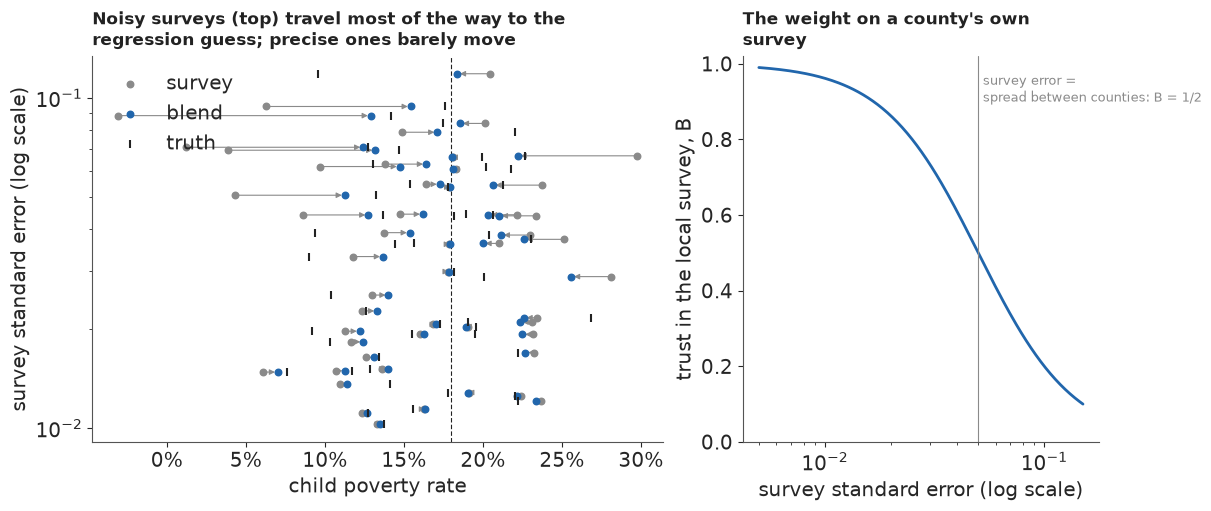

In [6]:
rng_b = np.random.default_rng(1979)
J, MU_B, SV_B = 50, 0.18, 0.05
s_b = np.sort(np.exp(rng_b.uniform(np.log(0.01), np.log(0.12), J)))
th_b = rng_b.normal(MU_B, SV_B, J)
y_b = th_b + s_b * rng_b.normal(size=J)
B_b = SV_B**2 / (SV_B**2 + s_b**2)
blend_b = B_b * y_b + (1 - B_b) * MU_B
rmse = lambda e: float(np.sqrt(np.mean(e**2)))
print(f"error against the truth (points): survey {100 * rmse(y_b - th_b):.1f}, "
      f"blend {100 * rmse(blend_b - th_b):.1f}")
closer = (np.abs(blend_b - th_b) < np.abs(y_b - th_b)).sum()
print(f"the blend is closer for {closer} of {J} counties")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), width_ratios=[1.6, 1])
ax = axes[0]
for k in range(J):
    ax.annotate("", (blend_b[k], s_b[k]), (y_b[k], s_b[k]),
                arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=0.8, mutation_scale=8))
ax.scatter(y_b, s_b, s=22, color=MUTED, label="survey")
ax.scatter(blend_b, s_b, s=22, color=HI, label="blend", zorder=3)
ax.scatter(th_b, s_b, s=30, marker="|", color=INK, label="truth", zorder=4)
ax.axvline(MU_B, color=INK, lw=0.8, ls=(0, (4, 2)))
ax.set(yscale="log", xlabel="child poverty rate", ylabel="survey standard error (log scale)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="upper left", frameon=False)
pub._title(ax, "Noisy surveys (top) travel most of the way to the regression guess; precise ones "
           "barely move")
ax = axes[1]
sg = np.geomspace(0.005, 0.15, 200)
ax.plot(sg, SV_B**2 / (SV_B**2 + sg**2), color=HI, lw=2)
ax.axvline(SV_B, color=MUTED, lw=0.8)
ax.text(SV_B * 1.05, 0.9, "survey error =\nspread between counties: B = 1/2", fontsize=9.5,
        color=MUTED)
ax.set(xscale="log", xlabel="survey standard error (log scale)",
       ylabel="trust in the local survey, B", ylim=(0, 1.02))
pub._title(ax, "The weight on a county's own survey");

The blend almost halves the error against the truth (from 5.3 to 2.8 points) and is closer for
33 of the 50 counties, though not for all: a county that really is far from the mean gets pulled
towards it, the price of the gain on average. Here we knew the mean, the spread and each survey's
error. On real data the first two must be estimated, which is what a hierarchical model does, and
the third, it will turn out, cannot be trusted.

## C · The classic model on 3,142 counties

### The model

Proportions live in $[0, 1]$, so we work on the logit scale, as SAIPE does in spirit (it models
log counts). The survey enters as $y_i = \operatorname{logit}(p_i)$ with the delta-method standard
error $s_i = \mathrm{se}_i / \{p_i(1-p_i)\}$; a zero estimate is moved to $(0.5)/(N_i + 1)$ so
that its logit exists. The regression guess uses what every county has: its state, its
rural-urban continuum code (nine levels, from metro areas of a million or more to remote rural
counties) and its population:

$$\theta_i = \beta_0 + \beta^{\text{rucc}}_{r(i)} + \beta^{\text{pop}} z_i + u_{s(i)} + v_i,
  \qquad u_s \sim \mathcal N(0, \sigma_{\text{state}}^2),
  \quad v_i \sim \mathcal N(0, \sigma_v^2).$$

The rurality and state effects are zero-sum, so the intercept is the average county. Priors are
weakly informative on the logit scale: $\beta_0 \sim \mathcal N(-1.5, 1)$ (a rate near 18%, give
or take a factor of three), effect scales half-normal with scale 0.5 (a county one sd from its
neighbours has a rate about 1.6 times theirs). Every model in this notebook shares this mean part.

In [7]:
STATES = sorted(D["fips"].str[:2].unique())
ST_IDX = pd.Index(STATES).get_indexer(D["fips"].str[:2])
R_IDX = D["rucc"].astype(int).to_numpy() - 1
LPOP = np.log(D["pop2020"].to_numpy(float))
Z_POP = (LPOP - LPOP.mean()) / LPOP.std()
LN = np.log(N)
Z_N = (LN - LN.mean()) / LN.std()
Z_N18 = (np.log(N18) - LN.mean()) / LN.std()
COORDS = {"county": D["fips"].to_numpy(dtype=object), "state": STATES, "rucc": np.arange(1, 10)}
P_ADJ = np.where(ZERO, (X + 0.5) / (N + 1.0), P)
Y_LOGIT = logit(P_ADJ)
SE_LOGIT = SE / (P_ADJ * (1 - P_ADJ))


def mean_part():
    """Regression guess shared by every model: intercept, rurality, population, state."""
    b0 = pm.Normal("b0", -1.5, 1.0)
    b_r = pm.ZeroSumNormal("b_rucc", 0.5, dims="rucc")
    b_pop = pm.Normal("b_pop", 0.0, 0.5)
    s_state = pm.HalfNormal("sigma_state", 0.5)
    u = pm.ZeroSumNormal("u_state", s_state, dims="state")
    mu = pm.Deterministic("mu", b0 + b_r[R_IDX] + b_pop * Z_POP + u[ST_IDX], dims="county")
    return mu, pm.HalfNormal("sigma_v", 0.5)


with pm.Model(coords=COORDS) as m_classic:
    mu, s_v = mean_part()
    theta = pm.Normal("theta", mu, s_v, dims="county")
    pm.Normal("y", theta, SE_LOGIT, observed=Y_LOGIT, dims="county")

prior = pm.sample_prior_predictive(draws=300, model=m_classic, var_names=["theta"],
                                   random_seed=RANDOM_SEED)
prior_rates = expit(prior.prior["theta"].values.ravel())
print("prior predictive county rates, 5/50/95%:",
      np.quantile(prior_rates, [0.05, 0.5, 0.95]).round(3),
      "| observed survey:", np.quantile(P, [0.05, 0.5, 0.95]).round(3))
print(f"prior share of county rates above 60%: {(prior_rates > 0.6).mean():.1%}")

prior predictive county rates, 5/50/95%: [0.023 0.176 0.691] | observed survey: [0.058 0.169 0.37 ]
prior share of county rates above 60%: 8.4%


The prior allows county rates from about 2% to 70% in its central 90%, against the surveys' 6-37%,
and puts 8% of counties above 60%: generous, but without piling mass at 0 or 1. It knows what a
proportion is and little else, which is what we want before 3,142 surveys speak.

### The fit

All fits use nutpie, PyMC's default sampler here, with 4 chains of 1,000 draws; each fit keeps
every fourth draw (1,000 in all) of the county rates for what follows, and the full posterior is
then deleted to keep the notebook small.

In [8]:
def fit(label, model, globals_, tune=None, check=()):
    """Sample, print diagnostics, keep thinned NumPy draws (county x 1000) and drop the rest.

    `check` names further county-level variables whose r_hat and ESS are printed, then dropped."""
    t0 = time.time()
    keep = ["theta", "mu"] + globals_
    idata = pm.sample(model=model, random_seed=RANDOM_SEED, progressbar=False,
                      var_names=keep + ["b_rucc", "u_state", "b_pop", "b0", "sigma_state"]
                      + list(check), **({} if tune is None else {"tune": tune}))
    TIMES[label] = time.time() - t0
    post = idata.posterior
    div = int(idata.sample_stats["diverging"].sum())
    worst = {v: (float(az.rhat(post[v]).max()), float(az.ess(post[v]).min()))
             for v in ["theta", "u_state", "b_rucc"] + list(check) + globals_}
    print(f"[{label}] {TIMES[label]:.0f} s, {post.attrs['tuning_steps']} tuning steps, "
          f"{div} divergences")
    print("   worst r_hat / smallest bulk ESS:",
          ", ".join(f"{v} {r:.3f}/{e:.0f}" for v, (r, e) in worst.items()))
    out = {v: post[v].stack(s=("chain", "draw")).transpose("county", "s").values[:, ::4]
           for v in ("theta", "mu")}
    for v in globals_ + ["b0", "sigma_state", "b_pop"]:
        out[v] = post[v].values.reshape(-1)[::4]
    out["b_rucc"] = post["b_rucc"].median(("chain", "draw")).values
    out["u_state"] = post["u_state"].median(("chain", "draw")).values
    out["divergences"] = div
    del idata
    return out


F_CLASSIC = fit("classic", m_classic, ["sigma_v"])
th_c = F_CLASSIC["theta"]
print(f"sigma_v {np.median(F_CLASSIC['sigma_v']):.2f}, sigma_state "
      f"{np.median(F_CLASSIC['sigma_state']):.2f}, b_pop {np.median(F_CLASSIC['b_pop']):+.2f}")
print("rurality effects (logit, 1 = big metro ... 9 = remote rural):", F_CLASSIC["b_rucc"].round(2))
u_c = pd.Series(F_CLASSIC["u_state"],
                index=[D["state"][ST_IDX == k].iloc[0] for k in range(len(STATES))])
print("state effects, highest:", u_c.nlargest(4).round(2).to_dict(), " lowest:",
      u_c.nsmallest(4).round(2).to_dict())

[classic] 6 s, 400 tuning steps, 0 divergences
   worst r_hat / smallest bulk ESS: theta 1.008/3635, u_state 1.004/1401, b_rucc 1.002/1880, sigma_v 1.001/2559
sigma_v 0.46, sigma_state 0.36, b_pop -0.00
rurality effects (logit, 1 = big metro ... 9 = remote rural): [-0.41 -0.15 -0.07  0.05  0.07  0.11  0.1   0.1   0.19]
state effects, highest: {'LA': 0.73, 'MS': 0.72, 'AL': 0.56, 'NM': 0.54}  lowest: {'NE': -0.58, 'NH': -0.55, 'UT': -0.52, 'MN': -0.48}


Under ten seconds, compilation included, no divergences, and every r_hat near 1 over 3,142
county rates. The between-county spread is about 0.46 on the logit scale, against about 0.36
between states. Rurality matters at the edges: the biggest metro areas sit about 0.4 below the
average county, the remote rural ones about 0.2 above. Population adds nothing once rurality is
known ($\beta^{\text{pop}}$ near 0). The state effects run from Nebraska, New Hampshire, Utah and
Minnesota at the bottom to Louisiana, Mississippi, Alabama and New Mexico at the top.

### Does the model reproduce the surveys?

A posterior predictive check that redraws each $y_i$ around its own fitted $\theta_i$ cannot fail
here, because every county has its own parameter. The useful check is **mixed**: draw a new
county effect from $\mathcal N(\mu_i, \sigma_v^2)$, then a new survey from it, and ask whether the
real survey looks like a draw from that, by size.

In [9]:
mu_c = F_CLASSIC["mu"]
sv_c = F_CLASSIC["sigma_v"]
th_new = mu_c + sv_c[None, :] * rng.normal(size=mu_c.shape)
y_rep = th_new + SE_LOGIT[:, None] * rng.normal(size=mu_c.shape)
lo_r, hi_r = np.quantile(y_rep, [0.055, 0.945], axis=1)
inside = (Y_LOGIT >= lo_r) & (Y_LOGIT <= hi_r)
print("share of surveys inside their 89% mixed predictive interval, by size fifth:",
      [f"{inside[Q == k].mean():.0%}" for k in range(5)], f" all {inside.mean():.1%}")
B_c = np.clip(1 - th_c.var(axis=1) / np.median(sv_c) ** 2, 0, 1)
print("trust in the local survey B, median by size fifth:",
      [round(float(np.median(B_c[Q == k])), 2) for k in range(5)])
p_c = np.median(expit(th_c), axis=1)
print(f"Mason County, TX: survey 0 of {N[IDX['48319']]:.0f} children -> classic estimate "
      f"{p_c[IDX['48319']]:.0%}")
del th_new, y_rep

share of surveys inside their 89% mixed predictive interval, by size fifth: ['83%', '89%', '91%', '94%', '91%']  all 89.4%
trust in the local survey B, median by size fifth: [0.66, 0.82, 0.86, 0.92, 0.97]


Mason County, TX: survey 0 of 914 children -> classic estimate 23%


Coverage is 89% overall, but 83% in the smallest fifth of counties against 89-94% in the others:
small counties' surveys stray from the model more often than their margins allow, the first sign
of part D. The trust weights follow part B: a median of 0.66 in the smallest fifth, rising to 0.97
in the largest. And Mason County, whose survey found no poor children, comes out at 23%.

That last number looks like success, but it comes from an accident. On the logit scale the
delta-method standard error of a proportion near zero is enormous ($s_i \approx \mathrm{se}_i /
p_i$), so the model gives Mason's survey almost no weight. The same arithmetic gives every low
survey a large error and every high one a small error, a bias built into the margins rather than
the data. The model is right for the wrong reason.

## D · What a margin of error does not tell you

### Two surveys of the same counties

The ACS 5-year sample for 2014-2018 shares no households with the one for 2019-2023, so for 3,130
counties we have a second, independent measurement, five years earlier. Child poverty fell
nationally from 19.6% to 16.3%, and counties changed by different amounts. If the margins are
right, the difference between a county's two surveys, after the national shift, should be normal
with the two sampling variances plus a variance $\tau^2$ for real change. Everything in this part
rests on one assumption: $\tau$ is the same for every county, learned from the largest fifth,
where sampling error is small. The next section puts bounds on it.

We work on the arcsine square-root scale, $a = \arcsin\sqrt{p}$, whose sampling variance is about
$\mathrm{se}^2 / \{4p(1-p)\}$ and, unlike the logit, stays finite at zero. Then

$$z_i = \frac{a^{23}_i - a^{18}_i - \text{shift}}{\sqrt{s^{2}_{23,i} + s^{2}_{18,i} + \tau^2}}$$

should be standard normal, and $|z_i| > 3$ should happen for 0.27% of counties.

real change between periods, sd (arcsine, largest fifth): 0.030
|z| > 3: 2.9% of counties (91), against 0.27% if the margins were right: 11 times
|z| > 4: 14 counties, against 0.2 expected
|z| > 3 by size fifth: ['6.1%', '5.6%', '1.4%', '1.4%', '0.0%']
sd of z 1.33, robust sd 1.26


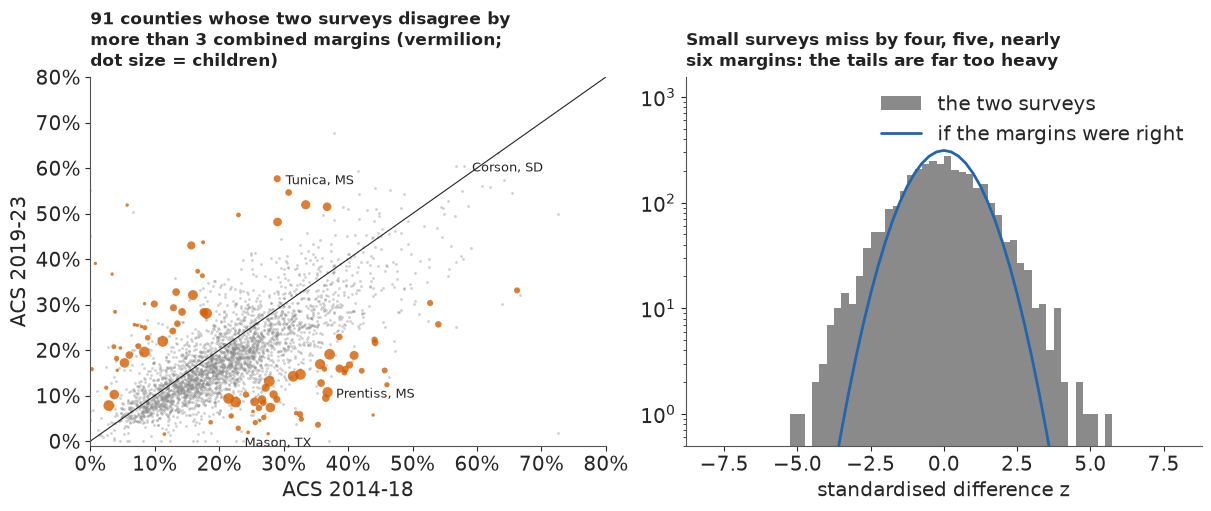

In [10]:
def asin_se(p, se, x, n):
    pf = np.where((p > 0) & (p < 1), p, np.clip((x + 0.5) / (n + 1), 0, 1))
    return se / (2 * np.sqrt(pf * (1 - pf)))


A23, A18 = np.arcsin(np.sqrt(P)), np.arcsin(np.sqrt(P18))
S23, S18 = asin_se(P, SE, X, N), asin_se(P18, SE18, X18, N18)
BIG = OK18 & (Q == 4)


def disagreement(a23, a18):
    diff = a23 - a18
    shift = np.median(diff[BIG])
    tau2 = max(np.var(diff[BIG] - shift) - np.mean(S23[BIG] ** 2 + S18[BIG] ** 2), 0.0)
    return (diff - shift) / np.sqrt(S23**2 + S18**2 + tau2), np.sqrt(tau2)


Z_DIS, TAU_BIG = disagreement(A23, A18)
z_ok = Z_DIS[OK18]
DIS_OBS = np.mean(np.abs(z_ok) > 3)
print(f"real change between periods, sd (arcsine, largest fifth): {TAU_BIG:.3f}")
print(f"|z| > 3: {DIS_OBS:.1%} of counties ({(np.abs(z_ok) > 3).sum()}), against "
      f"{2 * norm.sf(3):.2%} if the margins were right: {DIS_OBS / (2 * norm.sf(3)):.0f} times")
print(f"|z| > 4: {(np.abs(z_ok) > 4).sum()} counties, against "
      f"{2 * norm.sf(4) * OK18.sum():.1f} expected")
print("|z| > 3 by size fifth:",
      [f"{np.mean(np.abs(Z_DIS[OK18 & (Q == k)]) > 3):.1%}" for k in range(5)])
mad = 1.4826 * np.median(np.abs(z_ok - np.median(z_ok)))
print(f"sd of z {z_ok.std():.2f}, robust sd {mad:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
far = OK18 & (np.abs(Z_DIS) > 3)
ax.scatter(P18[OK18 & ~far], P[OK18 & ~far], s=4, color=MUTED, alpha=0.4, lw=0)
ax.scatter(P18[far], P[far], s=np.clip(N[far] / 100, 6, 60), color=LO, alpha=0.8, lw=0)
ax.plot([0, 0.8], [0, 0.8], color=INK, lw=0.8)
for f in ("48319", "28143", "46031", "28117"):
    i = IDX[f]
    ax.annotate(D["short"][i], (P18[i], P[i]), xytext=(6, -4), textcoords="offset points",
                fontsize=9)
ax.set(xlabel="ACS 2014-18", ylabel="ACS 2019-23", xlim=(0, 0.8), ylim=(-0.01, 0.8))
for f_ in (ax.xaxis, ax.yaxis):
    f_.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
pub._title(ax, f"{far.sum()} counties whose two surveys disagree by more than 3 combined margins "
           "(vermilion; dot size = children)")
ax = axes[1]
bins = np.linspace(-8, 8, 65)
ax.hist(z_ok, bins=bins, color=MUTED, label="the two surveys")
ax.plot(bins, OK18.sum() * (bins[1] - bins[0]) * norm.pdf(bins), color=HI, lw=2,
        label="if the margins were right")
ax.set(yscale="log", ylim=(0.5, None), xlabel="standardised difference z")
ax.legend(frameon=False)
pub._title(ax, "Small surveys miss by four, five, nearly six margins: the tails are far too heavy");

The two surveys disagree beyond three combined margins for 2.9% of counties, about **eleven
times** as often as the margins allow, and beyond four margins for 14 counties where we would
expect fewer than one. The excess is almost all in small counties: 6% in the smallest fifth (the
0% in the largest is no evidence, since $\tau$ was calibrated there). Even in the bulk the
differences are about a quarter wider than the margins imply (robust sd of $z$ 1.26).

### Is it the survey, or real change?

A small county could also simply change more: when a few dozen poor families move, its true rate
moves, with a variance of about $\kappa/(4N_i)$ on the arcsine scale. $\kappa$ would be about 2 if
every child's status were redrawn independently, a few times that if families move together.
This term has the form of a sampling variance, so adding it for several $\kappa$ only asks how
much extra variance of that shape would be needed; change that does not shrink as $1/N_i$, such
as a one-employer county losing its plant, is not covered. We also ask SAIPE, a 2023 estimate
built largely from tax and benefit records: if the disagreements were real change, SAIPE, which
tracks 2023 and shares part of that sample, should side with the recent survey in nearly every
disagreeing county. We compare within size fifths, because SAIPE leans on its regression in small
counties and on its 2023 one-year survey in large ones. We chose both checks after seeing the
excess.

In [11]:
def disagreement_churn(kappa):
    diff, ch = A23 - A18, kappa / (4 * N)
    shift = np.median(diff[BIG])
    tau2 = max(np.var(diff[BIG] - shift) - np.mean(S23[BIG] ** 2 + S18[BIG] ** 2 + ch[BIG]), 0.0)
    return (diff - shift) / np.sqrt(S23**2 + S18**2 + tau2 + ch)


for kappa in (0, 2, 5, 10, 20, 40):
    z_k = disagreement_churn(kappa)[OK18]
    print(f"kappa {kappa:3d}: |z| > 3 for {np.mean(np.abs(z_k) > 3):.1%} of counties "
          f"({np.mean(np.abs(z_k) > 3) / (2 * norm.sf(3)):.1f} times the nominal 0.27%)")
has_s = OK18 & ~np.isnan(SAIPE)
side_23 = np.abs(SAIPE - P) < np.abs(SAIPE - P18)
agree1 = has_s & (np.abs(Z_DIS) < 1)
print(f"SAIPE closer to the 2019-23 survey: {side_23[far & has_s].mean():.0%} where the surveys "
      f"disagree by more than 3 margins, {side_23[agree1].mean():.0%} where they agree within 1")
for k in range(4):
    fk, ak = far & has_s & (Q == k), agree1 & (Q == k)
    print(f"   size fifth {k + 1}: disagreeing {side_23[fk].mean():.0%} (n = {fk.sum()}), "
          f"agreeing {side_23[ak].mean():.0%} (n = {ak.sum()})")
w_far = np.bincount(Q[far & has_s], minlength=5) / (far & has_s).sum()
SIDE_MATCHED = sum(w_far[k] * side_23[agree1 & (Q == k)].mean() for k in range(5) if w_far[k] > 0)
print(f"agreeing counties reweighted to the sizes of the disagreeing ones: {SIDE_MATCHED:.0%}")

kappa   0: |z| > 3 for 2.9% of counties (10.8 times the nominal 0.27%)
kappa   2: |z| > 3 for 2.8% of counties (10.3 times the nominal 0.27%)
kappa   5: |z| > 3 for 2.3% of counties (8.6 times the nominal 0.27%)
kappa  10: |z| > 3 for 1.8% of counties (6.6 times the nominal 0.27%)
kappa  20: |z| > 3 for 1.3% of counties (4.7 times the nominal 0.27%)
kappa  40: |z| > 3 for 0.5% of counties (2.0 times the nominal 0.27%)
SAIPE closer to the 2019-23 survey: 54% where the surveys disagree by more than 3 margins, 64% where they agree within 1
   size fifth 1: disagreeing 37% (n = 38), agreeing 39% (n = 307)
   size fifth 2: disagreeing 63% (n = 35), agreeing 56% (n = 308)
   size fifth 3: disagreeing 78% (n = 9), agreeing 62% (n = 347)
   size fifth 4: disagreeing 67% (n = 9), agreeing 72% (n = 388)
agreeing counties reweighted to the sizes of the disagreeing ones: 51%


Churn of a plausible size changes little: with $\kappa = 5$ the surveys still disagree beyond
three margins about nine times too often, and even $\kappa = 40$, a change variance larger than a
whole survey's (design effect 27), leaves twice too many. SAIPE sides with the recent survey in
54% of the disagreeing counties, close to a coin toss and about as often as in agreeing counties
of the same sizes (51%); the 64% for all agreeing counties includes the large ones, where SAIPE
leans on the 2023 sample and the national fall pulls it towards the recent survey. Neither check
rules out change concentrated in small counties that does not scale as $1/N_i$. We read the
excess as survey error and keep one change variance for all counties; it is the main assumption
behind "small surveys miss more often than their margins say".

Why would they? An ACS margin is estimated from the same few dozen households as the estimate:
when the sample contains none of the county's poor families, the estimate is zero and the
variance estimate collapses with it. The sample is also clustered, so one unlucky draw of a few
blocks moves everything at once. Both make the errors heavy-tailed, and both hide from the margin.

### The variance as data

The remedy for unreliable variances is to model them, in two parts. The first is a **generalised
variance function** (GVF), the survey statistician's smooth summary of many variances (Wolter
2007): the sampling variance of $p_i$ is $c_i \pi_i(1-\pi_i)/N_i$, with $N_i$ the county's
children and $c_i$ a design effect that drifts smoothly with size, $\log c_i = g_0 + g_1
z^{N}_i$. We tie it to the true rate $\pi_i$ rather than the estimate, as Liu, Lahiri & Kalton
(2014) do for small-area proportions; on the arcsine scale the variance is then $c_i / (4N_i)$,
free of the rate. The second part follows You & Chapman (2006) in spirit: the published variances
become data. They give each area's variance a parameter of its own, with the published variance
as chi-square data about it; we keep only the smooth function, so each published variance
scatters around the GVF like a chi-square with $k$ degrees of freedom and the survey likelihood
uses the smooth variance, not the county's own,

$$r_i = \frac{\mathrm{se}_i^2 N_i}{p_i(1-p_i)} \sim \frac{c_i\, \chi^2_k}{k}
  \quad\Longleftrightarrow\quad r_i \sim \text{Gamma}\Big(\frac{k}{2}, \frac{k}{2c_i}\Big),$$

for counties with $0 < p_i < 1$, and the survey itself is $a_i \sim \mathcal
N(\arcsin\sqrt{\pi_i}, c_i/(4N_i))$. A zero estimate says that the estimate fell at or below
zero, so it enters as a censored observation, $\Pr(a_i \le 0)$. With a Student-t error later,
`pm.Censored` would evaluate the t CDF, with its incomplete beta functions, on every row;
densities for the positive rows plus a `pm.Potential` of log CDFs for the fourteen zero rows give
the same posterior far more cheaply. The priors are loose: $g_0 \sim \mathcal N(\log 20, 1)$
puts the design effect at 20 give or take a factor of $e$ (part A measured 27), $g_1 \sim
\mathcal N(0, 0.5)$ lets it grow or shrink with size, and $k \sim \text{Gamma}(2, 0.05)$ has a
mean of 40 degrees of freedom, so it is the data that must say the variances are noisy.

In [12]:
def gvf_sd(suffix, p, se, n, zn, rows):
    """Smooth design effect c = exp(g0 + g1 z_N), learned from the published variances."""
    g0 = pm.Normal(f"g0{suffix}", np.log(20.0), 1.0)
    g1 = pm.Normal(f"g1{suffix}", 0.0, 0.5)
    k = pm.Gamma(f"k{suffix}", 2.0, 0.05)
    c = pt.exp(g0 + g1 * zn)
    ok = rows[(p[rows] > 0) & (p[rows] < 1)]
    r = se[ok] ** 2 * n[ok] / (p[ok] * (1 - p[ok]))
    pm.Gamma(f"r_obs{suffix}", alpha=k / 2, beta=k / (2 * c[ok]), observed=r)
    return pt.sqrt(c / (4 * n))


def survey(name, a_obs, a_true, sd, nu_e, rows):
    """Survey likelihood on the arcsine scale; zeros as censored mass Pr(a <= 0)."""
    zr, pr = rows[a_obs[rows] == 0], rows[a_obs[rows] > 0]
    if nu_e is None:
        pm.Normal(f"{name}_pos", a_true[pr], sd[pr], observed=a_obs[pr])
        pm.Potential(f"{name}_zero", pm.logcdf(pm.Normal.dist(a_true[zr], sd[zr]), 0.0).sum())
    else:
        pm.StudentT(f"{name}_pos", nu=nu_e, mu=a_true[pr], sigma=sd[pr], observed=a_obs[pr])
        pm.Potential(f"{name}_zero",
                     pm.logcdf(pm.StudentT.dist(nu=nu_e, mu=a_true[zr], sigma=sd[zr]), 0.0).sum())


ALL = np.arange(n_cty)


def one_survey_model(t_errors, t_effects=False):
    with pm.Model(coords=COORDS) as m:
        mu, s_v = mean_part()
        if t_effects:
            nu = pm.Gamma("nu", 2.0, 0.1)
            theta = pm.StudentT("theta", nu=nu, mu=mu, sigma=s_v, dims="county")
        else:
            theta = pm.Normal("theta", mu, s_v, dims="county")
        sd = gvf_sd("", P, SE, N, Z_N, ALL)
        nu_e = pm.Gamma("nu_e", 2.0, 0.1) if t_errors else None
        survey("y", A23, pt.arcsin(pt.sqrt(pm.math.invlogit(theta))), sd, nu_e, ALL)
    return m


F_ONE_N = fit("one survey, normal errors", one_survey_model(False), ["sigma_v", "g0", "g1", "k"])
print(f"design effect at the average size exp(g0) = {np.exp(np.median(F_ONE_N['g0'])):.0f}, "
      f"g1 = {np.median(F_ONE_N['g1']):.2f}, k = {np.median(F_ONE_N['k']):.1f}")

[one survey, normal errors] 12 s, 400 tuning steps, 0 divergences
   worst r_hat / smallest bulk ESS: theta 1.007/3612, u_state 1.005/1636, b_rucc 1.002/2254, sigma_v 1.001/2634, g0 1.001/3972, g1 1.001/4263, k 1.003/4515
design effect at the average size exp(g0) = 27, g1 = 0.36, k = 9.3


The variance model fits: the design effect is about 27 for a county of average size and grows
with size ($g_1 \approx 0.36$, since the survey samples a smaller share of a big county), and the
published variances scatter around it like a chi-square with about 9 degrees of freedom. That
scatter mixes two things: the noise in each published variance, which is You & Chapman's point,
and real differences in design effect between counties of the same size, which a size-only
function cannot see. Either way a single county's margin is often off by a factor of two from
what its size implies. Sampling was clean. But look at what the model now believes.

### Failure 1: believing the zero

In [13]:
SHOW = {"48319": "zero survey", "48105": "zero survey", "48271": "zero survey",
        "46031": "Standing Rock", "46121": "Rosebud", "46102": "Pine Ridge",
        "38085": "Standing Rock",
        "28117": "surveys disagree", "28143": "surveys disagree"}
show_idx = [IDX[f] for f in SHOW]


def show_table(**models):
    t = pd.DataFrame({"county": D["short"][show_idx].to_numpy(), "": list(SHOW.values()),
                      "ACS 2019-23": P[show_idx], "ACS 2014-18": P18[show_idx],
                      "SAIPE 2023": SAIPE[show_idx]})
    for name, th in models.items():
        t[name] = np.median(expit(th[show_idx]), axis=1)
    num = t.columns[2:]
    t[num] = (100 * t[num]).round(0).astype(int)
    return t.to_string(index=False)


print("child poverty, %")
print(show_table(classic=th_c, one_normal=F_ONE_N["theta"]))

child poverty, %
           county                   ACS 2019-23  ACS 2014-18  SAIPE 2023  classic  one_normal
        Mason, TX      zero survey            0           23          21       23           6
     Crockett, TX      zero survey            0           37          21       21           6
       Kinney, TX      zero survey            0           28          26       22           9
       Corson, SD    Standing Rock           60           58          40       58          50
         Todd, SD          Rosebud           57           64          38       56          52
Oglala Lakota, SD       Pine Ridge           55           58          41       52          51
        Sioux, ND    Standing Rock           54           49          39       52          43
     Prentiss, MS surveys disagree           11           37          24       13          13
       Tunica, MS surveys disagree           58           29          42       50          52


With the variance tied to the true rate instead of the noisy estimate, the zero county's survey
gets the weight that a survey of 914 children deserves: Mason and Crockett counties fall to about
6%, Kinney to 9%, a third of what SAIPE says. The model has no way to doubt the zero: under a
normal error a survey that far from the truth is almost impossible, so the truth must be near the
survey. On the proportion scale, where the variance $c\pi(1-\pi)/N$ goes to zero with the rate,
the same idea would be worse still, since a zero estimate would then have an unbounded density at
$\pi = 0$. The classic model escaped this only through its accident.

Part D's first section already says what is wrong: the errors are heavy-tailed. The natural repair
is a Student-t survey error, $a_i \sim t_{\nu_e}(\arcsin\sqrt{\pi_i}, c_i/(4N_i))$, with $\nu_e$
learned from 3,000 counties under the Gamma(2, 0.1) prior of Juárez & Steel (2010), which has a
mean of 20 and leaves room for both very heavy and nearly normal tails.

### Failure 2: heavy tails from one survey cannot tell a fluke from a fact

In [14]:
F_ONE_T = fit("one survey, t errors", one_survey_model(True), ["sigma_v", "g0", "g1", "k", "nu_e"],
              tune=1000)
print(f"survey-error degrees of freedom nu_e = {np.median(F_ONE_T['nu_e']):.2f}, "
      f"sigma_v = {np.median(F_ONE_T['sigma_v']):.2f}")
print("child poverty, %")
print(show_table(classic=th_c, one_normal=F_ONE_N["theta"], one_t=F_ONE_T["theta"]))

[one survey, t errors] 32 s, 1000 tuning steps, 0 divergences
   worst r_hat / smallest bulk ESS: theta 1.011/1089, u_state 1.003/2776, b_rucc 1.001/3523, sigma_v 1.004/1275, g0 1.000/8081, g1 1.000/6604, k 1.003/7591, nu_e 1.007/697
survey-error degrees of freedom nu_e = 3.13, sigma_v = 0.41
child poverty, %
           county                   ACS 2019-23  ACS 2014-18  SAIPE 2023  classic  one_normal  one_t
        Mason, TX      zero survey            0           23          21       23           6     18
     Crockett, TX      zero survey            0           37          21       21           6     17
       Kinney, TX      zero survey            0           28          26       22           9     18
       Corson, SD    Standing Rock           60           58          40       58          50     19
         Todd, SD          Rosebud           57           64          38       56          52     20
Oglala Lakota, SD       Pine Ridge           55           58          41       52  

The data want very heavy tails, $\nu_e \approx 3$, and Mason County climbs back to the teens. The
sampler is happy. But the poorest counties in the country have gone with the zeros: Corson County,
whose survey found 60% of its children poor with a standard error of 2.4 points, is now estimated
at 19%, and Todd, Oglala Lakota and Sioux counties fall to 15-21%. Their earlier surveys found
49-64%. The model has decided that a survey far from what similar counties show is more likely a
survey failure than a real place, and with one survey per county nothing contradicts it.

Is that only because this model lets the survey errors, but not the county effects, have heavy
tails? We fit the same one-survey model once more with Student-t county effects as well, with the
same Gamma(2, 0.1) prior on their degrees of freedom $\nu$.

In [15]:
F_ONE_TT = fit("one survey, t errors and t effects", one_survey_model(True, True),
               ["sigma_v", "g0", "g1", "k", "nu_e", "nu"], tune=1000)
print(f"nu_e = {np.median(F_ONE_TT['nu_e']):.2f}, county-effect nu = "
      f"{np.median(F_ONE_TT['nu']):.0f} (89% {np.quantile(F_ONE_TT['nu'], 0.055):.0f}-"
      f"{np.quantile(F_ONE_TT['nu'], 0.945):.0f}; prior mean 20)")
print("child poverty, %")
print(show_table(one_t=F_ONE_T["theta"], one_t_t=F_ONE_TT["theta"]))
del F_ONE_TT

[one survey, t errors and t effects] 34 s, 1000 tuning steps, 0 divergences
   worst r_hat / smallest bulk ESS: theta 1.011/467, u_state 1.003/2926, b_rucc 1.002/2738, sigma_v 1.002/1461, g0 1.000/7607, g1 1.000/6122, k 1.005/11402, nu_e 1.008/512, nu 1.004/1591
nu_e = 3.25, county-effect nu = 21 (89% 11-47; prior mean 20)
child poverty, %
           county                   ACS 2019-23  ACS 2014-18  SAIPE 2023  one_t  one_t_t
        Mason, TX      zero survey            0           23          21     18       17
     Crockett, TX      zero survey            0           37          21     17       17
       Kinney, TX      zero survey            0           28          26     18       18
       Corson, SD    Standing Rock           60           58          40     19       19
         Todd, SD          Rosebud           57           64          38     20       22
Oglala Lakota, SD       Pine Ridge           55           58          41     21       24
        Sioux, ND    Standing Rock 

It changes almost nothing. The county effects' $\nu$ stays where its prior put it, around 20 and
poorly determined, the survey tail stays at about 3, and Corson, Todd, Oglala Lakota and Sioux
counties stay near 15-25%. A heavy tail on the survey and a heavy tail on the county effects are
two explanations of the same outlying number, and one number cannot choose between them; given
the choice, the fit puts the outliers in the survey, where 3,000 counties show heavy tails.

Model comparison does not catch this. Leave-one-out cross-validation scores each county's survey
given all the others. With one effect per county, leaving out a county's only survey moves its
effect a long way, so ordinary PSIS-LOO on $a_i$ given $\theta_i$ is unreliable. Instead we
integrate each county's rate out by quadrature and score the **marginal** predictive density
$p(a_i \mid \beta, \sigma_v, \nu_e, c)$ of the two models with normal county effects, which PSIS
handles well. Zero counties are left out, since their censored terms are not densities.

In [16]:
def marginal_ll(F, nu_e=None, rows=None, n_draws=500, grid=161, wide=False):
    """log p(a_i | globals) per county and draw, the county's rate integrated out on a grid.

    The grid spans a few survey sds around the survey; `wide` also covers the prior's range."""
    pick = np.linspace(0, F["mu"].shape[1] - 1, n_draws).round().astype(int)
    mu, sv = F["mu"][:, pick], F["sigma_v"][pick]
    logc = F["g0"][pick][None, :] + F["g1"][pick][None, :] * Z_N[:, None]
    sd = np.sqrt(np.exp(logc) / (4 * N[:, None]))
    nue = None if nu_e is None else F[nu_e][pick]
    rows = np.flatnonzero(~ZERO) if rows is None else rows
    ll = np.empty((rows.size, n_draws))
    for j, i in enumerate(rows):
        span = (8 if nue is None else 30) * sd[i].max()
        lo, hi = A23[i] - span, A23[i] + span
        if wide:
            lo = min(lo, np.arcsin(np.sqrt(expit(mu[i].min() - 8 * sv.max()))))
            hi = max(hi, np.arcsin(np.sqrt(expit(mu[i].max() + 8 * sv.max()))))
        a = np.linspace(max(1e-6, lo), min(np.pi / 2 - 1e-6, hi), grid)
        th = logit(np.sin(a) ** 2)
        lp = (norm.logpdf(th[None, :], mu[i][:, None], sv[:, None])
              + np.log(4 / np.sin(2 * a))[None, :])  # Jacobian from logit rate to arcsine
        if nue is None:
            lik = norm.logpdf(A23[i], a[None, :], sd[i][:, None])
        else:
            lik = tdist.logpdf(A23[i], nue[:, None], a[None, :], sd[i][:, None])
        ll[j] = logsumexp(lp + lik + np.log(np.gradient(a))[None, :], axis=1)
    return ll


def marginal_loo(F, nu_e=None):
    ll = marginal_ll(F, nu_e)
    tree = xr.DataTree.from_dict({
        "posterior": xr.Dataset({"dummy": (("chain", "draw"), np.zeros((1, ll.shape[1])))}),
        "log_likelihood": xr.Dataset({"y": (("chain", "draw", "county"), ll.T[None])})})
    return az.loo(tree, var_name="y", pointwise=True)


def conditional_k(F, nu_e):
    """Pareto k of ordinary PSIS-LOO: each survey given its own county's rate."""
    rows = np.flatnonzero(~ZERO)
    logc = F["g0"][None, :] + F["g1"][None, :] * Z_N[rows, None]
    sd = np.sqrt(np.exp(logc) / (4 * N[rows, None]))
    ll = tdist.logpdf(A23[rows, None], F[nu_e][None, :],
                      np.arcsin(np.sqrt(expit(F["theta"][rows]))), sd)
    tree = xr.DataTree.from_dict({
        "posterior": xr.Dataset({"dummy": (("chain", "draw"), np.zeros((1, ll.shape[1])))}),
        "log_likelihood": xr.Dataset({"y": (("chain", "draw", "county"), ll.T[None])})})
    return np.asarray(az.loo(tree, var_name="y", pointwise=True).pareto_k)


K_COND = conditional_k(F_ONE_T, "nu_e")
print(f"ordinary PSIS-LOO, one survey with t errors: Pareto k > 0.7 for "
      f"{(K_COND > 0.7).mean():.0%} of counties, > 1 for {(K_COND > 1).mean():.0%}")
t0 = time.time()
LOO = {"one survey, normal errors": marginal_loo(F_ONE_N),
       "one survey, t errors": marginal_loo(F_ONE_T, "nu_e")}
TIMES["marginal LOO"] = time.time() - t0
for name, lo in LOO.items():
    print(f"{name}: elpd {float(lo.elpd):.0f} (se {float(lo.se):.0f}), "
          f"Pareto k > 0.7: {int((np.asarray(lo.pareto_k) > 0.7).sum())}")
dl = (np.asarray(LOO["one survey, t errors"].elpd_i)
      - np.asarray(LOO["one survey, normal errors"].elpd_i))
print(f"t minus normal: {dl.sum():+.0f} +- {np.sqrt(dl.size) * dl.std():.0f}")
# quadrature check where the grid is narrowest: large counties, grid widened to the prior's range
big_rows = np.flatnonzero(~ZERO & (Q == 4))
lme = lambda ll: logsumexp(ll, axis=1) - np.log(ll.shape[1])
gap = lme(marginal_ll(F_ONE_T, "nu_e", big_rows)) - lme(
    marginal_ll(F_ONE_T, "nu_e", big_rows, grid=401, wide=True))
print(f"largest fifth, t errors: standard minus widened grid, summed log density {gap.sum():+.3f}, "
      f"largest single county {np.abs(gap).max():.4f}")

ordinary PSIS-LOO, one survey with t errors: Pareto k > 0.7 for 32% of counties, > 1 for 8%


one survey, normal errors: elpd 2823 (se 48), Pareto k > 0.7: 0
one survey, t errors: elpd 2855 (se 46), Pareto k > 0.7: 1
t minus normal: +32 +- 10


largest fifth, t errors: standard minus widened grid, summed log density -0.007, largest single county 0.0031


Ordinary PSIS-LOO bears that out: a third of the counties have Pareto $k$ above 0.7. On the
marginal scores, cross-validation prefers the heavy-tailed model clearly (by about 32 points of
expected log predictive density, three standard errors; one Pareto $k$ above 0.7), and the
quadrature is not the reason: widening the grid to the prior's whole range for the large
counties changes their summed log density by less than 0.01. The t errors predict the next
county's survey better, because surveys really do miss that way. What the score cannot say is
*which* surveys missed: Corson's is predicted well by both "a 20% county with an unlucky survey"
and "a 58% county with a good one". Diagnostics, divergences and LOO are all clean, and the model
is wrong exactly where the stakes are highest.

## E · Two surveys: telling a fluke from a fact

### The model

What separates a bad survey from a real outlier is replication. If Corson's 2014-18 survey also
says 58%, two independent heavy-tailed misses in the same direction are very unlikely. The final
model measures each county twice:

$$a^{23}_i \sim t_{\nu_e}\Big(\arcsin\sqrt{\pi_i},\ \tfrac{c^{23}_i}{4N^{23}_i}\Big), \qquad
  a^{18}_i \sim t_{\nu_e}\Big(\arcsin\sqrt{\pi^{18}_i},\ \tfrac{c^{18}_i}{4N^{18}_i}\Big),$$

$$\operatorname{logit}\pi^{18}_i = \operatorname{logit}\pi_i + \delta_0 + \tau_d\, w_i,
  \qquad w_i \sim \mathcal N(0, 1),$$

with a separate GVF for each survey, zeros censored in both, $\delta_0$ the national change and
$\tau_d$ the county-to-county spread of real change. Their priors are loose on the logit scale:
$\delta_0 \sim \mathcal N(0, 0.5)$ allows a national change of 10-20 points either way at 18%,
and $\tau_d \sim \text{HalfNormal}(0.3)$ typical county changes of up to about 4 points around
it. Real change is normal with one spread for every county, the assumption part D could only
bound. The county effects $v_i$ are Student-t with $\nu \sim \text{Gamma}(2, 0.1)$, as in the
last one-survey fit. We give the sampler 1,000 warm-up steps rather than nutpie's default 400,
because the tail parameters adapt slowly.

In [17]:
ROWS18 = np.flatnonzero(OK18)
with pm.Model(coords=COORDS) as m_two:
    mu, s_v = mean_part()
    nu = pm.Gamma("nu", 2.0, 0.1)
    theta = pm.StudentT("theta", nu=nu, mu=mu, sigma=s_v, dims="county")
    nu_e = pm.Gamma("nu_e", 2.0, 0.1)
    survey("y23", A23, pt.arcsin(pt.sqrt(pm.math.invlogit(theta))), gvf_sd("", P, SE, N, Z_N, ALL),
           nu_e, ALL)
    delta0 = pm.Normal("delta0", 0.0, 0.5)
    tau_d = pm.HalfNormal("tau_d", 0.3)
    w = pm.Normal("w", 0.0, 1.0, dims="county")
    theta18 = theta + delta0 + tau_d * w
    survey("y18", A18, pt.arcsin(pt.sqrt(pm.math.invlogit(theta18))),
           gvf_sd("18", P18, SE18, N18, Z_N18, ROWS18), nu_e, ROWS18)

F_TWO = fit("two surveys", m_two, ["sigma_v", "nu", "nu_e", "g0", "g1", "k", "g018", "g118", "k18",
                                   "delta0", "tau_d"], tune=1000, check=("w",))
th_2 = F_TWO["theta"]
for v in ["sigma_v", "nu", "nu_e", "delta0", "tau_d", "k", "k18"]:
    lo_, md_, hi_ = np.quantile(F_TWO[v], [0.055, 0.5, 0.945])
    print(f"   {v:8s} {md_:7.3f}  [{lo_:.3f}, {hi_:.3f}]")
print("child poverty, %")
print(show_table(classic=th_c, one_normal=F_ONE_N["theta"], one_t=F_ONE_T["theta"], two=th_2))

[two surveys] 84 s, 1000 tuning steps, 0 divergences
   worst r_hat / smallest bulk ESS: theta 1.008/1486, u_state 1.003/1994, b_rucc 1.002/2253, w 1.006/1287, sigma_v 1.001/1455, nu 1.000/1402, nu_e 1.001/1254, g0 1.002/7494, g1 1.001/7198, k 1.000/8858, g018 1.002/6389, g118 1.002/7714, k18 1.002/8410, delta0 1.001/1296, tau_d 1.001/495
   sigma_v    0.350  [0.334, 0.366]
   nu         6.936  [5.612, 9.180]
   nu_e       3.345  [3.093, 3.619]
   delta0     0.205  [0.197, 0.214]
   tau_d      0.126  [0.114, 0.138]
   k          9.263  [8.884, 9.630]
   k18       10.071  [9.656, 10.469]
child poverty, %
           county                   ACS 2019-23  ACS 2014-18  SAIPE 2023  classic  one_normal  one_t  two
        Mason, TX      zero survey            0           23          21       23           6     18   18
     Crockett, TX      zero survey            0           37          21       21           6     17   24
       Kinney, TX      zero survey            0           28          2

About a minute and a half, no divergences, r_hat at most about 1.01 over the 6,284 county
parameters (rates and change effects). The fitted tails are telling. Survey errors keep their
heavy tail, $\nu_e \approx 3.3$, so a small survey that misses by five margins is ordinary. County
effects now get a heavy tail of their own, $\nu \approx 7$, which one survey per county could not
support: the same prior stayed near 20 in the last one-survey fit. Child poverty fell by about
0.2 on the logit scale between the periods (from 19.6% to 16.3% nationally), and real change
between counties is small, $\tau_d \approx 0.13$, so the two surveys are close to replicates.

The table shows what that buys. The reservation counties keep their high rates, because both
surveys agree: Todd about 57%, Oglala Lakota and Corson 53%. The zeros are discounted: Mason
County comes back to about 18%, Crockett and Kinney to the twenties, close to SAIPE. Where the
two surveys disagree, the model sides with the one closer to what similar counties show: the
earlier survey for Prentiss County, Mississippi (11% now, 37% before), giving 29% against SAIPE's
24%, and also for Tunica County (58% now, 29% before), giving 25% where SAIPE says 42%. Two
surveys can outvote one; they cannot always tell which of two is wrong.

### Does it reproduce the disagreement?

The check that matters is the one the single-survey models could not face: replicate both surveys
from the posterior, with the model's own errors, and recompute the share of counties whose surveys
disagree by more than three margins, with the same statistic and the same published margins.

In [18]:
def ppc_disagreement(F, n_rep=200):
    reps = []
    for j in rng.choice(F["theta"].shape[1], n_rep, replace=False):
        t23 = F["theta"][:, j]
        t18 = t23 + F["delta0"][j] + F["tau_d"][j] * rng.normal(size=n_cty)
        sd23 = np.sqrt(np.exp(F["g0"][j] + F["g1"][j] * Z_N) / (4 * N))
        sd18 = np.sqrt(np.exp(F["g018"][j] + F["g118"][j] * Z_N18) / (4 * N18))
        e = rng.standard_t(F["nu_e"][j], (2, n_cty))
        y23 = np.clip(np.arcsin(np.sqrt(expit(t23))) + sd23 * e[0], 0, np.pi / 2)
        y18 = np.clip(np.arcsin(np.sqrt(expit(t18))) + sd18 * e[1], 0, np.pi / 2)
        reps.append(np.mean(np.abs(disagreement(y23, y18)[0][OK18]) > 3))
    return np.array(reps)


DIS_REP = ppc_disagreement(F_TWO)
print(f"share of counties with |z| > 3: observed {DIS_OBS:.1%}; replicated median "
      f"{np.median(DIS_REP):.1%}, 89% [{np.quantile(DIS_REP, 0.055):.1%}, "
      f"{np.quantile(DIS_REP, 0.945):.1%}]")

share of counties with |z| > 3: observed 2.9%; replicated median 3.5%, 89% [2.9%, 4.4%]


The model roughly reproduces the disagreement, a little high: about 3.5% of replicated counties
disagree by more than three margins (89% range 2.9-4.4%), against 2.9% observed, where normal
errors would give the 0.3% the margins promise. The observed share sits at the bottom edge of the
range, so the fitted survey tail is a little heavier than the data need, which errs on the side
of doubting a lone survey.

### Who moves

A funnel of the estimates beside part A's funnel of the surveys shows where the model changed the
picture.

median |estimate - survey| (points) by size fifth: [3.8, 2.3, 1.7, 0.9, 0.4]
counties moved by more than 10 points: 130


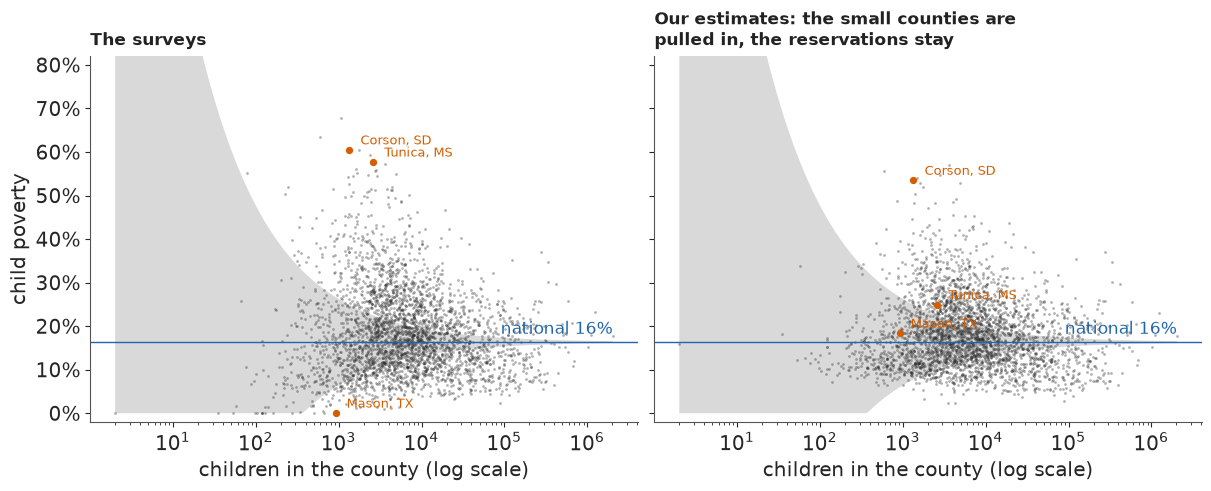

In [19]:
p_2 = np.median(expit(th_2), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
funnel(axes[0], P, "The surveys", ("48319", "46031", "28143"))
funnel(axes[1], p_2, "Our estimates: the small counties are pulled in, the reservations stay",
       ("48319", "46031", "28143"))
axes[0].set_ylabel("child poverty")
move = np.abs(p_2 - P)
print("median |estimate - survey| (points) by size fifth:",
      [round(float(np.median(move[Q == k]) * 100), 1) for k in range(5)])
print("counties moved by more than 10 points:", int((move > 0.10).sum()));

The left side of the funnel closes. The median county in the smallest fifth moves by about four
points, the median in the largest by under half a point. The handful of very poor counties at the
top left stay where they are, because two surveys put them there.

## F · Checking against the Census Bureau

SAIPE is the Census Bureau's official county estimate. Its covariates are tax and food-assistance
(SNAP) records, which reach every family, but the quantity it models is the single-year ACS
estimate for 2023, about a fifth of the 2019-23 sample we use. So SAIPE is not the truth and only
partly independent of our data, though far better informed; we never used it in a fit. For each
model we compute the mean gap to SAIPE and count the counties where the two agree within 1.6
combined standard deviations, an 89% band.

In [20]:
def against_saipe(est, sd):
    ok = ~np.isnan(SAIPE)
    e = est - SAIPE
    agree = np.abs(e) < 1.598 * np.sqrt(sd**2 + SAIPE_SE**2)
    row = {"MAE (pts)": 100 * np.nanmean(np.abs(e)),
           "MAE smallest fifth": 100 * np.nanmean(np.abs(e[Q == 0])),
           "agree": np.mean(agree[ok]), "agree smallest fifth": np.mean(agree[ok & (Q == 0)])}
    for k in range(5):
        row[f"bias q{k + 1}"] = 100 * np.nanmean(e[Q == k])
    return row


def est_sd(th):
    pi = expit(th)
    return np.median(pi, axis=1), pi.std(axis=1)


SAIPE_TAB = pd.DataFrame({"direct survey": against_saipe(P, SE),
                          "classic": against_saipe(*est_sd(th_c)),
                          "one survey, normal": against_saipe(*est_sd(F_ONE_N["theta"])),
                          "one survey, t": against_saipe(*est_sd(F_ONE_T["theta"])),
                          "two surveys": against_saipe(*est_sd(th_2))}).T
print(SAIPE_TAB.round(2).to_string())
q1 = (Q == 0) & ~np.isnan(SAIPE)
print("bias in the smallest fifth with posterior MEANS instead of medians (points):",
      {k: round(float(100 * np.mean(expit(th[q1]).mean(axis=1) - SAIPE[q1])), 2)
       for k, th in [("classic", th_c), ("one survey, normal", F_ONE_N["theta"]),
                     ("one survey, t", F_ONE_T["theta"]), ("two surveys", th_2)]})
print("reservation counties, child poverty %: two-survey estimate against SAIPE (90% bounds)")
for f in ("46121", "46102", "46031", "38085"):
    i = IDX[f]
    print(f"   {D['short'][i]:18s} {100 * p_2[i]:3.0f}   SAIPE {100 * SAIPE[i]:3.0f} "
          f"({D['saipe_lo'][i]:.0f}-{D['saipe_hi'][i]:.0f})")

                    MAE (pts)  MAE smallest fifth  agree  agree smallest fifth  bias q1  bias q2  bias q3  bias q4  bias q5
direct survey            3.97                7.40   0.84                  0.71    -2.77    -0.33    -0.12     0.32     0.40
classic                  3.23                5.15   0.90                  0.84    -2.22    -0.45    -0.08     0.34     0.42
one survey, normal       3.33                5.50   0.90                  0.83    -3.13    -0.72    -0.26     0.25     0.38
one survey, t            3.13                5.08   0.95                  0.90    -3.48    -1.11    -0.37     0.24     0.38
two surveys              2.72                4.62   0.94                  0.88    -3.23    -1.10    -0.29     0.17     0.37
bias in the smallest fifth with posterior MEANS instead of medians (points): {'classic': -1.89, 'one survey, normal': -2.86, 'one survey, t': -3.18, 'two surveys': -3.05}
reservation counties, child poverty %: two-survey estimate against SAIPE (90% bounds)

Every model moves closer to SAIPE than the raw survey. The mean absolute gap falls from about 4.0
points for the survey to 3.2 for the classic model and 2.7 for the two-survey model, and 94% of
counties agree within the combined uncertainty, against 84% for the survey alone. Since SAIPE
shares the 2023 sample and shrinks towards a similar regression, agreement is no proof of
accuracy. The one-survey t model, which explained away the reservations, even agrees slightly
*more* often (95%): an agreement rate over 3,142 counties is a poor guide to the dozen that
matter most.

In the smallest fifth every estimate sits below SAIPE, and the direct survey itself is about 2.8
points lower. The models with a variance function add 0.1 to 0.7 points. With posterior means
instead of medians the normal-error model is within about 0.1 point of the survey, so its extra
gap is the median of a right-skewed rate; the t models stay 0.3-0.4 points lower even with means,
because heavy tails discount a lone high survey more readily than a low one (Tunica again). The
rest we cannot referee: SAIPE's records may see poverty that small samples miss, or its model may
pull small counties up.

The reservation counties need a warning of their own. Two ACS samples share the questionnaire,
the frame and the pattern of nonresponse, so replication cannot detect a bias common to both,
and there SAIPE is 6-19 points lower than our estimates: Todd and Oglala Lakota counties lie
outside SAIPE's own 90% bounds. SAIPE is not the referee in one direction only: its records and
its regression have errors of their own, and nothing here says which side is right. What survives
is the direction: SAIPE's 38-41% is still about three times the 10-14% that similar counties of
these states would lead one to expect.

A scatter against SAIPE shows the gain where it happens, in the small counties.

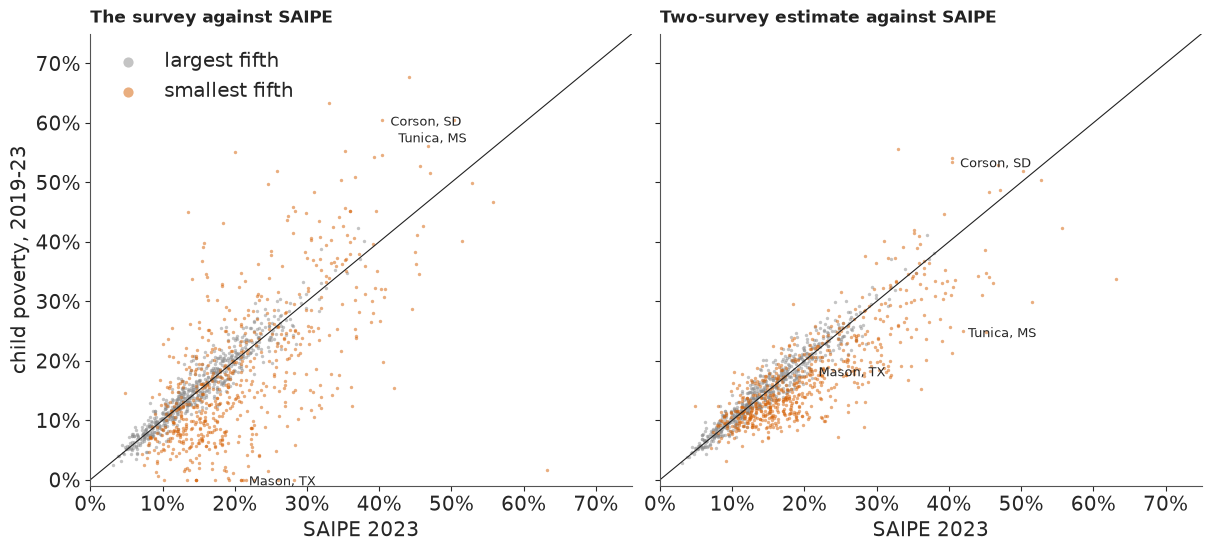

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharex=True, sharey=True)
for ax, est, ttl in [(axes[0], P, "The survey against SAIPE"),
                     (axes[1], p_2, "Two-survey estimate against SAIPE")]:
    for k, col, lab in [(4, MUTED, "largest fifth"), (0, LO, "smallest fifth")]:
        ax.scatter(SAIPE[Q == k], est[Q == k], s=6, color=col, alpha=0.5, lw=0, label=lab)
    ax.plot([0, 0.75], [0, 0.75], color=INK, lw=0.8)
    for f in ("28143", "46031", "48319"):
        i = IDX[f]
        ax.annotate(D["short"][i], (SAIPE[i], est[i]), xytext=(6, -4), textcoords="offset points",
                    fontsize=9)
    ax.set(xlabel="SAIPE 2023", xlim=(0, 0.75), ylim=(-0.01, 0.75))
    for f_ in (ax.xaxis, ax.yaxis):
        f_.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    pub._title(ax, ttl)
axes[0].set_ylabel("child poverty, 2019-23")
axes[0].legend(frameon=False, loc="upper left", markerscale=3);

The vermilion cloud of small counties tightens around the diagonal; the grey cloud of large ones
hardly changes, as it should. Tunica County jumps from well above the diagonal (survey 58%) to
well below it (estimate 25%): the case where the model trusted the wrong survey.

## G · Ranking with honesty

"The poorest county in America" is a favourite headline, and a ranking is where uncertainty is
easiest to forget. From the posterior draws we rank all 3,142 counties in each draw and count how
often each lands in the 50 highest, and in the 10 highest.

P(top 50) > 0.9: 17 counties; > 0.5: 41; > 0.05: 125;  P(top 10) > 0.5: 9
           county  children  estimate %  P(top 10)  P(top 50) rank 89%
Oglala Lakota, SD      4853        53.0       0.80      0.999     3-18
         Todd, SD      3627        57.0       0.96      0.999     1-10
       Zavala, TX      2810        55.0       0.87      0.995     1-15
       Zapata, TX      4404        49.0       0.36      0.985     5-33
       Holmes, MS      3985        49.0       0.29      0.984     6-33
    Jefferson, MS      1497        54.0       0.78      0.980     1-26
       Greene, AL      1622        53.0       0.71      0.975     1-30
      Leflore, MS      7212        45.0       0.04      0.960    12-46
      Madison, LA      2461        48.0       0.28      0.958     5-44
       Corson, SD      1343        53.0       0.71      0.957     1-37
        Perry, AL      1747        52.0       0.61      0.956     2-44
 East Carroll, LA      1416        50.0       0.50      0.937     1-56
   

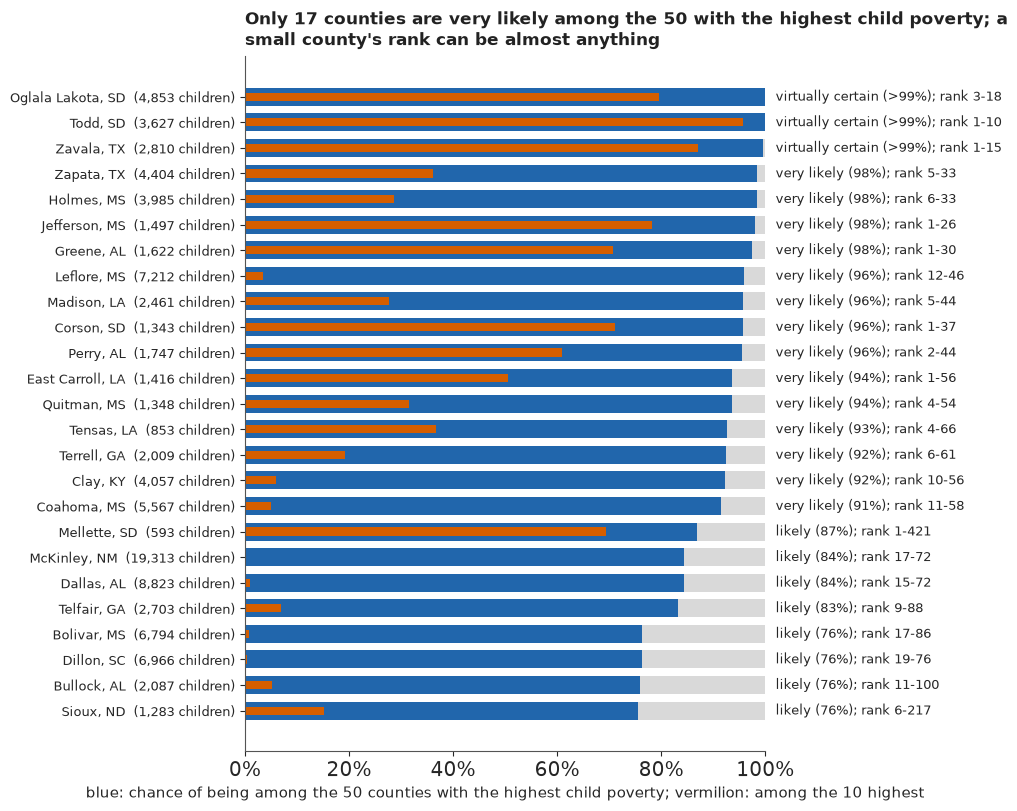

In [22]:
PI_2 = expit(th_2)
RANKS = (-PI_2).argsort(axis=0).argsort(axis=0) + 1  # 1 = highest child poverty, per draw
P_TOP50 = (RANKS <= 50).mean(axis=1)
P_TOP10 = (RANKS <= 10).mean(axis=1)
print(f"P(top 50) > 0.9: {(P_TOP50 > 0.9).sum()} counties; > 0.5: {(P_TOP50 > 0.5).sum()}; "
      f"> 0.05: {(P_TOP50 > 0.05).sum()};  P(top 10) > 0.5: {(P_TOP10 > 0.5).sum()}")
o = np.argsort(-P_TOP50)[:25]
LADDER = pd.DataFrame({"county": D["short"][o].to_numpy(), "children": N[o].astype(int),
                       "estimate %": (100 * p_2[o]).round(0), "P(top 10)": P_TOP10[o].round(2),
                       "P(top 50)": P_TOP50[o].round(3),
                       "rank 89%": [f"{a:.0f}-{b:.0f}" for a, b in
                                    np.quantile(RANKS[o], [0.055, 0.945], axis=1).T]})
print(LADDER.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 8))
for r, i in enumerate(o):
    ax.barh(r, P_TOP50[i], color=HI, height=0.7)
    ax.barh(r, 1 - P_TOP50[i], left=P_TOP50[i], color=LIGHT, height=0.7)
    ax.barh(r, P_TOP10[i], color=LO, height=0.32)
    rk = np.quantile(RANKS[i], [0.055, 0.945])
    ax.text(1.02, r, f"{pub.calibrated_word(P_TOP50[i])} ({pub.fmt_pct(P_TOP50[i])}); "
            f"rank {rk[0]:.0f}-{rk[1]:.0f}", va="center", fontsize=9.5)
ax.set_yticks(range(len(o)), [f"{D['short'][i]}  ({N[i]:,.0f} children)" for i in o], fontsize=9.5)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("blue: chance of being among the 50 counties with the highest child poverty; "
              "vermilion: among the 10 highest", fontsize=10.5)
pub._title(ax, f"Only {(P_TOP50 > 0.9).sum()} counties are very likely among the 50 with the "
           "highest child poverty; a small county's rank can be almost anything");

Seventeen counties are very likely in the top 50, and about 40 are more likely in than out, out of
about 125 with a real chance (over 5%). Todd and Oglala Lakota counties in South Dakota and Zavala
County, Texas, are almost certainly there; their ranks could still be anywhere from about 1 to 18.
Look at Mellette County, South Dakota: likely to be in the top 50 (87%), yet with fewer than 600
children its 89% rank interval runs from 1 to the hundreds, because the heavy tails leave room for
a much lower truth. In a published "top 10" list only Todd would be very likely (96%); Zavala and
Oglala Lakota are likely (87% and 80%), and of the nine counties more likely in than out, two
(Perry, Alabama, and East Carroll Parish, Louisiana) are close to a coin toss.

## H · Explaining it to everyone

### The statistician's version

The conventional output of a small-area study is a choropleth of the estimates and a caterpillar
plot of every interval. Here is the raw-survey map that a newsroom would draw first, and the
caterpillar of our 3,142 estimates.

3,131 of 3,142 counties drawn; 17 polygons with no county in the data (Connecticut's old counties, Valdez-Cordova) hatched


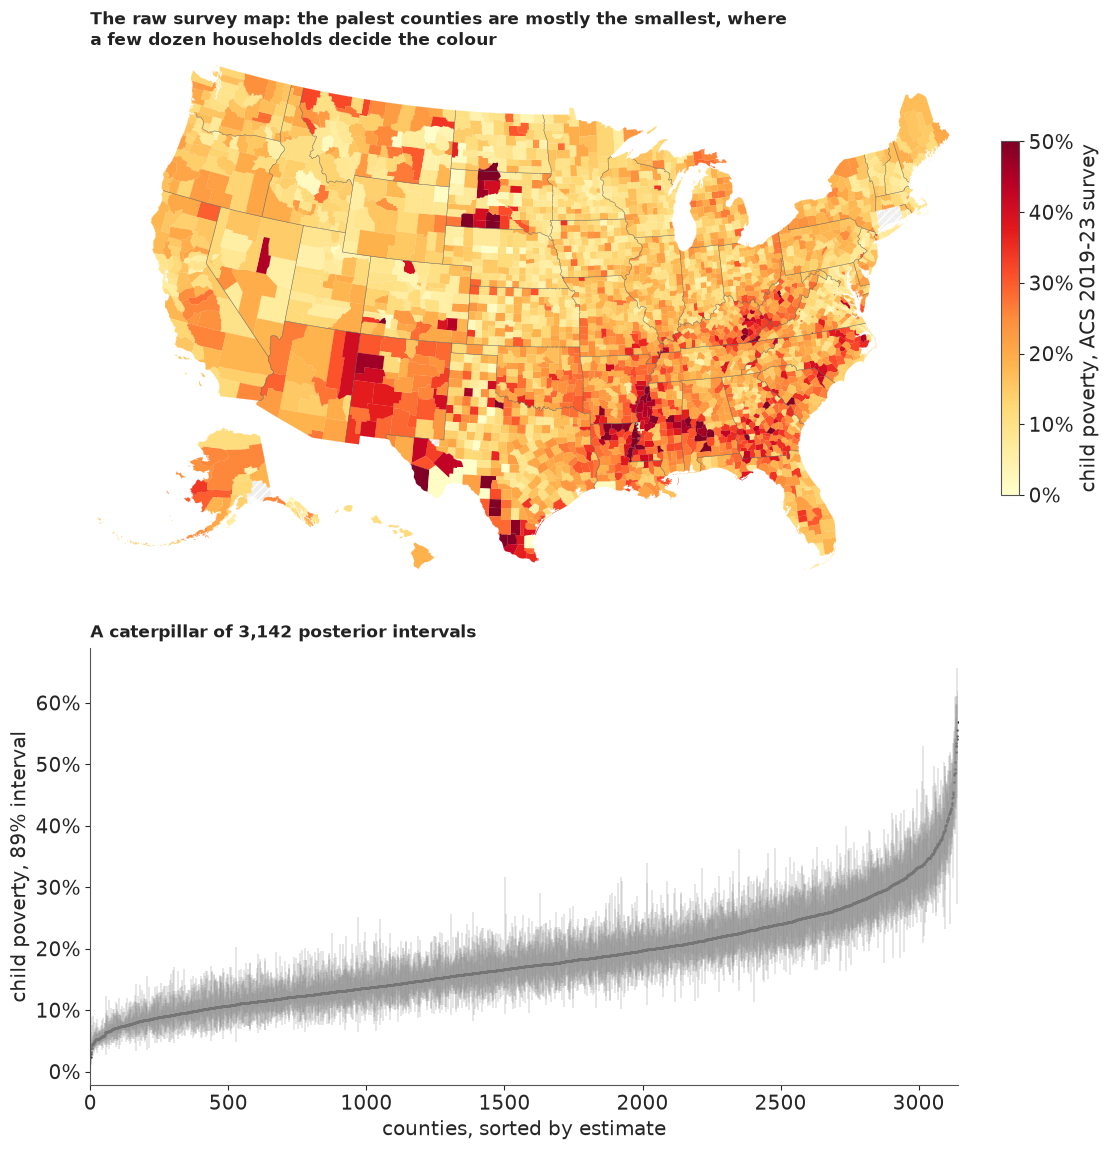

In [23]:
def albers(lon, lat, lon0=-96.0, lat0=37.5, p1=29.5, p2=45.5, radius=6371.0):
    lon, lat, lon0, lat0, p1, p2 = map(np.radians, (lon, lat, lon0, lat0, p1, p2))
    n = (np.sin(p1) + np.sin(p2)) / 2
    c = np.cos(p1) ** 2 + 2 * n * np.sin(p1)
    rho = radius * np.sqrt(c - 2 * n * np.sin(lat)) / n
    rho0 = radius * np.sqrt(c - 2 * n * np.sin(lat0)) / n
    return rho * np.sin(n * (lon - lon0)), rho0 - rho * np.cos(n * (lon - lon0))


def project(fips, ring):
    lon, lat = ring[:, 0], ring[:, 1]
    if fips.startswith("02"):  # Alaska: its own projection, shrunk, lower left
        x, y = albers(np.where(lon > 0, lon - 360, lon), lat, -154, 50, 55, 65)
        return np.column_stack([0.35 * x - 1900, 0.35 * y - 1350])
    if fips.startswith("15"):
        x, y = albers(lon, lat, -157, 13, 8, 18)
        return np.column_stack([x - 950, y - 1994])
    return np.column_stack(albers(lon, lat))


GEO_FIX = {"46113": "46102", "02270": "02158"}  # Shannon -> Oglala Lakota, Wade Hampton -> Kusilvak
VERTS, OWNER, GREY = [], [], []
with open(data.path("us_counties_geojson")) as fh:
    for feat in json.load(fh)["features"]:
        fid = GEO_FIX.get(feat["id"], feat["id"])
        if fid.startswith("72"):
            continue
        g = feat["geometry"]
        for poly in [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]:
            v = project(fid, np.asarray(poly[0], float)[:, :2])
            if fid in IDX:
                VERTS.append(v)
                OWNER.append(IDX[fid])
            else:
                GREY.append(v)  # Connecticut's old counties, Valdez-Cordova (split in 2019)
OWNER = np.array(OWNER)
edges = {}
for ring, o_ in zip(VERTS, OWNER):
    r_ = np.round(ring, 2)
    for a, b in zip(map(tuple, r_[:-1]), map(tuple, r_[1:])):
        edges.setdefault((a, b) if a < b else (b, a), set()).add(ST_IDX[o_])
BORDERS = np.array([e for e, s in edges.items() if len(s) > 1])
CENTRE = {}
for v, o_ in zip(VERTS, OWNER):
    CENTRE.setdefault(o_, []).append(v.mean(0))
CENTRE = {o_: np.mean(c_, axis=0) for o_, c_ in CENTRE.items()}
print(f"{len(set(OWNER)):,} of {n_cty:,} counties drawn; {len(GREY)} polygons with no county in "
      "the data (Connecticut's old counties, Valdez-Cordova) hatched")
XL, YL = (-2700, 2300), (-1400, 1620)


def base_map(ax, ylim=YL):
    ax.add_collection(PolyCollection(GREY, facecolor="#eeeeee", edgecolor="white", linewidth=0.15,
                                     hatch="////"))
    ax.set(xlim=XL, ylim=ylim, aspect="equal")
    ax.axis("off")


def borders(ax):
    ax.add_collection(LineCollection(BORDERS, colors="#555555", linewidths=0.35))


fig, axes = plt.subplots(2, 1, figsize=(11, 11.5), height_ratios=[1.35, 1])
ax = axes[0]
base_map(ax)
pc = PolyCollection(VERTS, array=P[OWNER], cmap="YlOrRd", edgecolor="face", linewidth=0.1,
                    clim=(0, 0.5))
ax.add_collection(pc)
borders(ax)
fig.colorbar(pc, ax=ax, shrink=0.6, label="child poverty, ACS 2019-23 survey",
             format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
pub._title(ax, "The raw survey map: the palest counties are mostly the smallest, where a few dozen "
           "households decide the colour")
ax = axes[1]
o_c = np.argsort(p_2)
lo2, hi2 = np.quantile(PI_2, [0.055, 0.945], axis=1)
ax.vlines(np.arange(n_cty), lo2[o_c], hi2[o_c], color=MUTED, lw=0.3)
ax.scatter(np.arange(n_cty), p_2[o_c], s=0.5, color=INK)
ax.set(xlabel="counties, sorted by estimate", ylabel="child poverty, 89% interval", xlim=(0, n_cty))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
pub._title(ax, "A caterpillar of 3,142 posterior intervals");

Both are honest and neither helps a reader. The raw map's palest yellows go largely to small
counties with the least reliable surveys: Mason and Crockett counties show up as the least poor
places in Texas. Its darkest reds mix real poverty, on the reservations and in the Delta, with
small-sample noise. The caterpillar contains every number in this notebook and answers no
question anyone asks: which county is it, and is it unusual? A map of our estimates would be
better, but still mixes two things a reader wants kept apart: how poor a county is, and whether
that is news.

### Surprise: where the data change what we expected

Correll & Heer's surprise map colours each county by how far its data move belief across a small
set of expectations. Ours has three: child poverty is about the national rate; about the state's
rate; about the rate for counties of this state and rural-urban type (the fitted $\mu_i$). Each
expectation $m$ predicts a county's true rate, $\operatorname{logit}\pi_i \sim \mathcal N(M_{m,i},
\text{spread}_m^2)$, with the spread defined the same way for all three: the root-mean-square
distance of the counties' posterior rates from that expectation. Starting from weight $1/3$ on
each, a county's data $D_i$ (both surveys, with everything the model knows about their errors)
update the weights by Bayes' rule, and the surprise is the Kullback-Leibler divergence of the
updated weights from the prior ones, signed by whether the county is above or below expectation:

$$\Pr(m \mid D_i) \propto \tfrac13\, p(D_i \mid m), \qquad
  S_i = \pm \sum_m \Pr(m \mid D_i) \log \frac{\Pr(m \mid D_i)}{1/3}.$$

The likelihood $p(D_i \mid m)$ comes from the fitted model without refitting: the posterior draws
of $\theta_i$ already combine both surveys with heavy-tailed errors, so reweighting them by the
ratio of expectation $m$'s density to the model's own prior density gives $p(D_i \mid m)$ up to a
constant shared by all three. $S_i$ is 0 when the data leave the three expectations equally
credible and at most $\log 3 \approx 1.10$ when they rule out two of them. We say a county stands
out when $|S_i|$ exceeds half that maximum, which takes roughly four-fifths or more of the weight
on one expectation (0.76 if the rest sits on one other, 0.84 if it is split evenly). The weight
need not go to an expectation that fits: it goes to the one that misses least badly.

In [24]:
STATE_RATE = (D.groupby(D["fips"].str[:2])["n_poor"].transform("sum")
              / D.groupby(D["fips"].str[:2])["n_children"].transform("sum")).to_numpy()
MU_MED = np.median(F_TWO["mu"], axis=1)
EXPECT = np.vstack([np.full(n_cty, logit(NAT)), logit(STATE_RATE), MU_MED])
TH_MED = np.median(th_2, axis=1)
SPREAD = np.array([np.sqrt(np.mean((th_2 - e_[:, None]) ** 2)) for e_ in EXPECT])
LP_PRIOR = tdist.logpdf(th_2, F_TWO["nu"][None, :], F_TWO["mu"], F_TWO["sigma_v"][None, :])


def surprise(spread, models=(0, 1, 2), weights=False):
    ll = np.empty((len(models), n_cty))
    for j, m_ in enumerate(models):
        lr = norm.logpdf(th_2, EXPECT[m_][:, None], spread[m_]) - LP_PRIOR
        ll[j] = logsumexp(lr, axis=1) - np.log(lr.shape[1])
    prior_m = np.full(len(models), 1 / len(models))
    post_m = np.exp(ll - ll.max(0)) * prior_m[:, None]
    post_m /= post_m.sum(0)
    kl = (post_m * np.log(np.maximum(post_m, 1e-300) / prior_m[:, None])).sum(0)
    s_ = np.sign(TH_MED - (prior_m[:, None] * EXPECT[list(models)]).sum(0)) * kl
    return (s_, post_m) if weights else s_


S, W_POST = surprise(SPREAD, weights=True)
THRESH = np.log(3) / 2
STAND = np.abs(S) > THRESH
EXP_NAMES = np.array(["national", "state", "state-and-type"])
# compiled by hand, not from Census files: counties that hold most of a large American Indian
# reservation or its tribal trust land (Mellette, SD: Rosebud trust land outside the reservation
# as diminished in 1977), or several Alaska Native villages; checked for the counties near the top
# of the surprise ranking only (it is not a complete list)
NATIVE = {"46102", "46121", "46031", "46137", "46041", "46017", "46095", "46007", "46071", "38085",
          "38079", "38005", "30035", "30003", "30085", "04001", "35031", "55078", "02158", "02050",
          "02185", "02188", "02164", "02070", "02290", "02180", "31173", "27087", "49037"}
print("spreads (logit) around the national, state and state-and-type expectations:",
      SPREAD.round(2))
print(f"stand out: {STAND.sum()} ({(S > THRESH).sum()} higher, {(S < -THRESH).sum()} lower)")
print("mean |surprise| by size fifth:",
      [round(float(np.abs(S[Q == k]).mean()), 3) for k in range(5)])
print("raw |survey - national| by size fifth:",
      [round(float(np.abs(P[Q == k] - NAT).mean()), 3) for k in range(5)])
so = np.argsort(-np.abs(S))[:STAND.sum() + 8]  # the standouts and the next eight
STAND_TAB = pd.DataFrame({"county": D["short"][so].to_numpy(), "surprise": S[so].round(2),
                          "ACS 2019-23 %": (100 * P[so]).round(0),
                          "ACS 2014-18 %": (100 * P18[so]).round(0),
                          "expected %": (100 * expit(MU_MED[so])).round(0),
                          "estimate %": (100 * p_2[so]).round(0), "children": N[so].astype(int),
                          "weight on": [f"{EXP_NAMES[W_POST[:, i].argmax()]} "
                                        f"{W_POST[:, i].max():.2f}" for i in so],
                          "native": [f in NATIVE for f in D["fips"][so]]})
print(STAND_TAB.to_string(index=False))
N_NATIVE = int(STAND_TAB.loc[STAND_TAB.surprise > THRESH, "native"].sum())
HIGH_ROWS = np.flatnonzero(S > THRESH)
DAKOTAS = bool(np.isin(D["state"][HIGH_ROWS], ["ND", "SD"]).all())
print(f"of the {HIGH_ROWS.size} higher: {N_NATIVE} hold reservations, tribal trust land or Alaska "
      f"Native villages; all in the Dakotas: {DAKOTAS}")

spreads (logit) around the national, state and state-and-type expectations: [0.57 0.47 0.41]
stand out: 8 (7 higher, 1 lower)
mean |surprise| by size fifth: [0.04, 0.044, 0.047, 0.037, 0.053]
raw |survey - national| by size fifth: [0.095, 0.085, 0.076, 0.06, 0.055]
             county  surprise  ACS 2019-23 %  ACS 2014-18 %  expected %  estimate %  children     weight on  native
          Sioux, ND      1.00           54.0           49.0        10.0        45.0      1283 national 0.98    True
     Los Alamos, NM     -0.99            3.0            5.0        27.0         5.0      4129 national 0.98   False
           Todd, SD      0.89           57.0           64.0        14.0        57.0      3627 national 0.95    True
  Oglala Lakota, SD      0.82           55.0           58.0        14.0        53.0      4853 national 0.93    True
         Benson, ND      0.78           30.0           53.0        10.0        31.0      1967 national 0.92    True
         Corson, SD      0.74         

Eight counties stand out, and seven of them are higher than expected: Sioux, Benson and Rolette
in North Dakota (the Standing Rock, Spirit Lake and Turtle Mountain reservations) and Todd, Oglala
Lakota and Corson in South Dakota (Rosebud, Pine Ridge and Standing Rock), with Mellette, whose
tribal land is Rosebud trust land outside the reservation's present boundary. Expected near
10-14% for rural counties of their states, their surveys put child poverty at 29-64%. For every
one of them the weight goes to the national rate, the broadest expectation, and even that misses
by 14-41 points: they stand out because they are far from all three. The one county lower than
expected is Los Alamos, New Mexico, the home of the national laboratory, expected at about 27% for
a small county of its type in New Mexico and estimated near 5%.

Just below the threshold sit Baltimore city and Ziebach County (Cheyenne River), higher than
expected; Cameron Parish, Louisiana, a rural coastal parish, and the suburban counties of Oldham,
Kentucky, and Williamson, Tennessee, lower; and King and Queen County, Virginia, higher, a rural
county whose expectation is a low metro rate because it lies in the Richmond metro area.

Mean surprise no longer falls with county size: it is 0.04-0.05 in every fifth, if anything
highest in the largest, while the raw distance from the national rate falls from 0.095 in the
smallest fifth to 0.055 in the largest. The surprise map is not a map of sample size.

### The headline figure, built properly

The public figure stacks surprise, in a diverging palette centred at zero, over our estimate on a
**value-suppressing uncertainty palette** (VSUP; Correll, Moritz & Heer 2018, who found that it
made viewers weigh uncertainty more than an ordinary bivariate map): four shades where the 89%
interval is narrower than 8 points, two shades faded halfway to grey up to 16 points, and grey
beyond. Surprise is not a rate, so it is never shown alone (Correll & Heer's own warning), and
counties without an outline are hatched, so that "no shape" never looks like "no poverty".

counties by interval width (<8, 8-16, >16 points): [1951 1091  100]


Once survey noise is weighed, child poverty is surprisingly high in 7 counties, all of them Dakota counties with American Indian reservations or tribal land, and surprisingly low in Los Alamos, NM


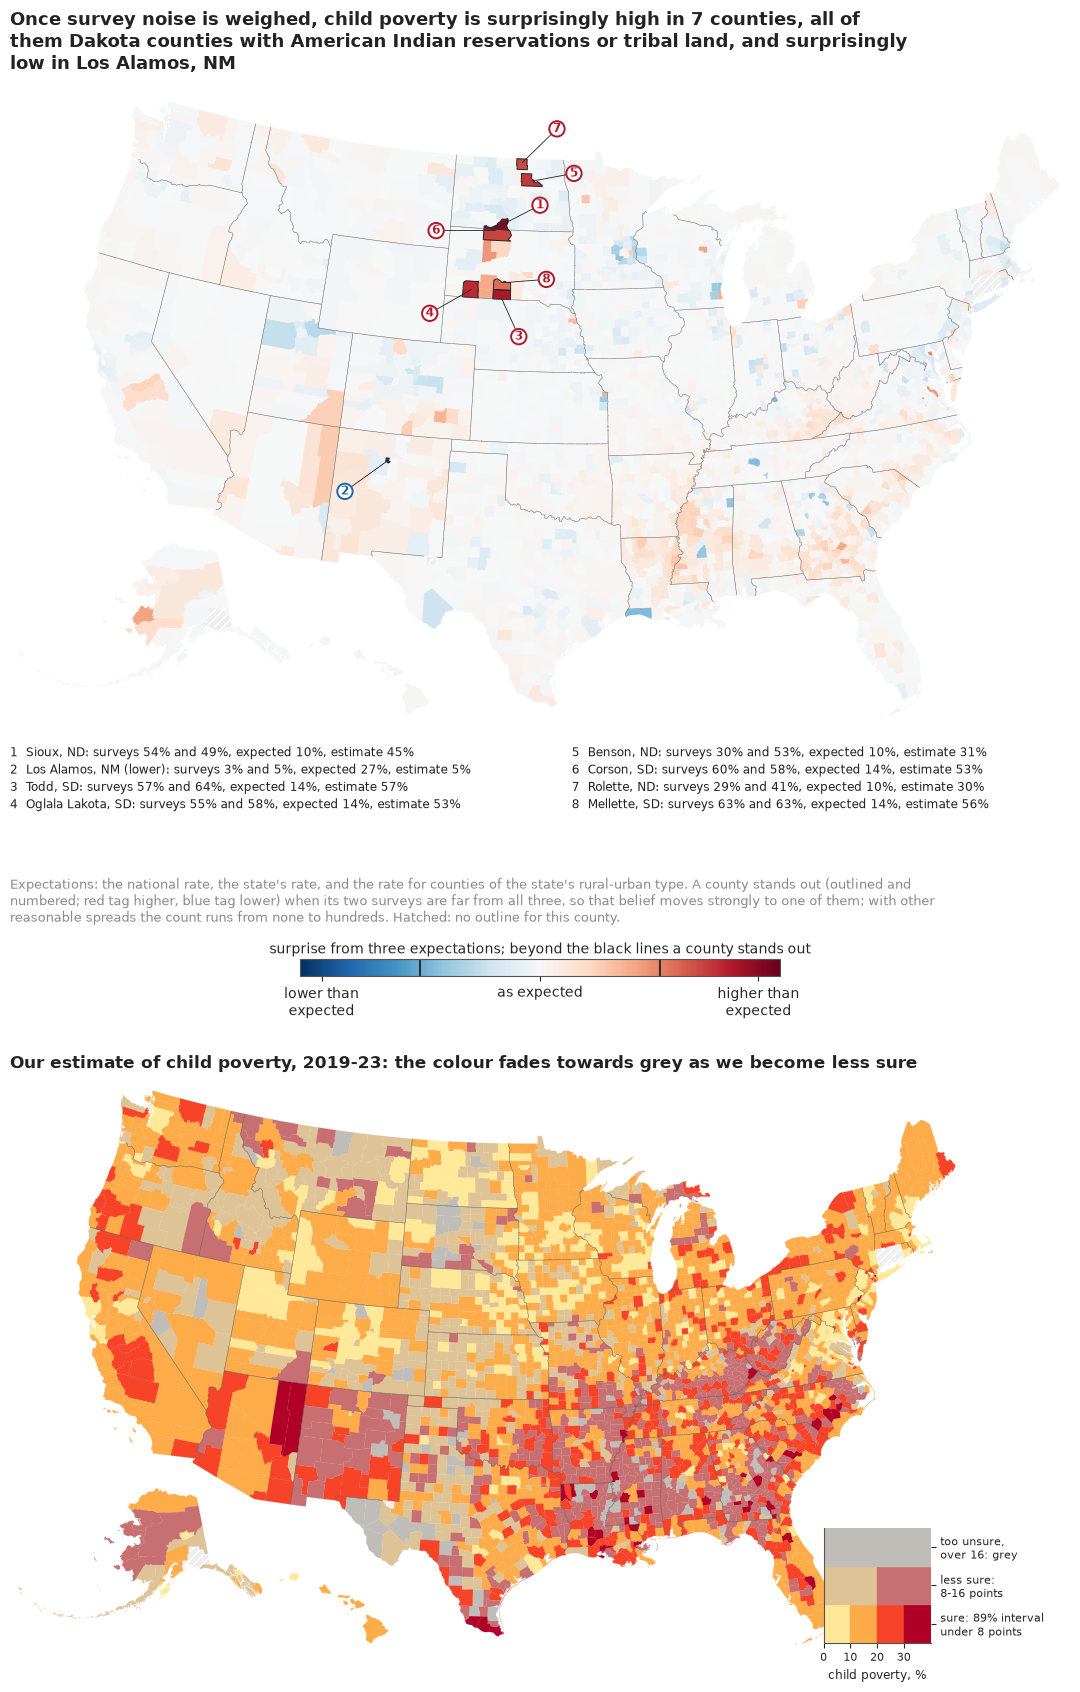

In [25]:
VALUE_COLS = [plt.get_cmap("YlOrRd")(v) for v in (0.15, 0.4, 0.65, 0.9)]
GREYC = np.array(to_rgb("#bdbdbd"))
mix = lambda c, w: tuple((1 - w) * np.asarray(to_rgb(c)) + w * GREYC)
VSUP_ROWS = [[mix(c, 0.0) for c in VALUE_COLS],
             [mix(np.mean([VALUE_COLS[0], VALUE_COLS[1]], axis=0)[:3], 0.5),
              mix(np.mean([VALUE_COLS[2], VALUE_COLS[3]], axis=0)[:3], 0.5)],
             [mix(VALUE_COLS[1], 0.95)]]
WIDTH = hi2 - lo2
VBIN = np.digitize(p_2, [0.10, 0.20, 0.30])
UBIN = np.digitize(WIDTH, [0.08, 0.16])
VSUP = np.array([VSUP_ROWS[u][v if u == 0 else (v // 2 if u == 1 else 0)]
                 for u, v in zip(UBIN, VBIN)])
print("counties by interval width (<8, 8-16, >16 points):", np.bincount(UBIN, minlength=3))
EXP_PCT = expit(MU_MED)
STAND_ORDER = np.argsort(-np.abs(S))[:STAND.sum()]  # numbered on the map, most surprising first
# where each number tag goes (map coordinates); other standouts get a small default offset
TAGS = {"38079": (-120, 1430), "38005": (-40, 1220), "38085": (-200, 1070), "46031": (-690, 950),
        "46102": (-720, 560), "46121": (-300, 450), "46095": (-170, 720), "35028": (-1120, -280),
        "46137": (-780, 790), "46007": (-640, 400), "24510": (1900, 520), "02158": (-2350, -760)}
N_HIGH, N_LOW = int((S > THRESH).sum()), int((S < -THRESH).sum())
LOW_TXT = (f"in {D['short'][np.flatnonzero(S < -THRESH)[0]]}" if N_LOW == 1
           else f"in {N_LOW} counties")
if N_NATIVE == N_HIGH and DAKOTAS:
    WHO = "all of them Dakota counties with American Indian reservations or tribal land"
elif N_NATIVE == N_HIGH:
    WHO = "all of them counties with American Indian reservations, tribal land or Alaska villages"
else:
    WHO = f"{N_NATIVE} of them with American Indian reservations, tribal land or Alaska villages"
HEAD_TITLE = (f"Once survey noise is weighed, child poverty is surprisingly high in {N_HIGH} "
              f"counties, {WHO}, and surprisingly low {LOW_TXT}")
CMAP_S = plt.get_cmap("RdBu_r")
TAG_EDGE = {True: CMAP_S(0.9), False: CMAP_S(0.1)}  # red tag: higher; blue tag: lower


def headline_figure():
    """Surprise map over a VSUP estimate map, with a fixed layout (both renderings identical)."""
    W, H = 11.0, 16.7  # inches; each map's box has its data aspect, so nothing is rescaled
    fig = plt.figure(figsize=(W, H), layout="none")
    rect = lambda left, bottom, width, height: [left / W, bottom / H, width / W, height / H]
    ax = fig.add_axes(rect(0.2, 7.4, 10.6, 10.6 * 3990 / 5000))
    base_map(ax, (-2330, 1660))
    pc = PolyCollection(VERTS, array=S[OWNER], cmap=CMAP_S,
                        norm=TwoSlopeNorm(0, -np.log(3), np.log(3)), edgecolor="face",
                        linewidth=0.1)
    ax.add_collection(pc)
    borders(ax)
    is_stand = np.isin(OWNER, STAND_ORDER)
    ax.add_collection(PolyCollection([v for v, s_ in zip(VERTS, is_stand) if s_],
                                     facecolor="none", edgecolor=INK, linewidth=0.7))
    cax = fig.add_axes(rect(3.1, 6.9, 4.8, 0.17))
    cb = fig.colorbar(pc, cax=cax, orientation="horizontal", ticks=[-1, 0, 1])
    cb.ax.set_xticklabels(["lower than\nexpected", "as expected", "higher than\nexpected"],
                          fontsize=10)
    for t_ in (-THRESH, THRESH):
        cb.ax.axvline(t_, color=INK, lw=1.3)
    cb.ax.xaxis.set_label_position("top")
    cb.set_label("surprise from three expectations; beyond the black lines a county stands out",
                 fontsize=10)
    key = []
    for k, i in enumerate(STAND_ORDER, 1):
        c_ = CENTRE[i]
        tx, ty = TAGS.get(D["fips"][i], (c_[0] + 160, c_[1] + 160))
        edge = TAG_EDGE[bool(S[i] > 0)]
        ax.annotate(str(k), c_, xytext=(tx, ty), fontsize=8.5, fontweight="bold", ha="center",
                    va="center", color=edge,
                    bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec=edge, lw=1.4),
                    arrowprops=dict(arrowstyle="-", lw=0.6, color=INK, shrinkA=0, shrinkB=0))
        key.append(f"{k}  {D['short'][i]}{'' if S[i] > 0 else ' (lower)'}: surveys {P[i]:.0%} "
                   f"and {P18[i]:.0%}, expected {EXP_PCT[i]:.0%}, estimate {p_2[i]:.0%}")
    half = (len(key) + 1) // 2
    for col_, chunk in enumerate([key[:half], key[half:]]):
        ax.text(0.0 + col_ * 0.53, 0.215, "\n".join(chunk), fontsize=8.6, va="top", color=INK,
                linespacing=1.45, transform=ax.transAxes)
    pub._title(ax, textwrap.fill(HEAD_TITLE, 88), fontsize=13, wrap=False)
    ax.text(0.0, 0.0, textwrap.fill(
        "Expectations: the national rate, the state's rate, and the rate for counties of the "
        "state's rural-urban type. A county stands out (outlined and numbered; red tag higher, "
        "blue tag lower) when its two surveys are far from all three, so that belief moves "
        "strongly to one of them; with other reasonable spreads the count runs from none to "
        "hundreds. Hatched: no outline for this county.", 150),
        fontsize=9, color=MUTED, va="bottom", transform=ax.transAxes)
    ax = fig.add_axes(rect(0.2, 0.1, 10.6, 10.6 * 3020 / 5550))
    base_map(ax)
    ax.set_xlim(XL[0], 2850)
    ax.add_collection(PolyCollection(VERTS, facecolors=VSUP[OWNER], edgecolor="face",
                                     linewidth=0.1))
    borders(ax)
    lax = ax.inset_axes([1560, -1330, 560, 600], transform=ax.transData)  # the Atlantic
    for r_, row_ in enumerate(VSUP_ROWS):
        w_ = 4 / len(row_)
        for c_, col in enumerate(row_):
            lax.add_patch(plt.Rectangle((c_ * w_, r_), w_, 1, color=col))
    lax.set(xlim=(0, 4), ylim=(0, 3), xticks=[0, 1, 2, 3], yticks=[0.5, 1.5, 2.5])
    lax.yaxis.tick_right()
    lax.set_xticklabels(["0", "10", "20", "30"], fontsize=8)
    lax.set_yticklabels(["sure: 89% interval\nunder 8 points", "less sure:\n8-16 points",
                         "too unsure,\nover 16: grey"], fontsize=8)
    lax.set_xlabel("child poverty, %", fontsize=8.5)
    pub._title(ax, "Our estimate of child poverty, 2019-23: the colour fades towards grey as we "
               "become less sure", fontsize=12)
    return fig


fig_top = headline_figure()
HEADLINE.update(fig_top)  # the copy at the top of the notebook
plt.close(fig_top)
fig_head = headline_figure()
print(HEAD_TITLE)

The top map is mostly pale, which is its message: for almost every county, including the small
ones that shouted on the raw map, the data are what one of the three plain expectations would
predict. Outlines and numbers mark the eight counties beyond the threshold drawn on the colour
bar, with red tags for higher and a blue tag for Los Alamos, too small to show its colour, and
the key gives both surveys, the expectation and our estimate for each.

The bottom map answers the other question, how poor a county is, and it is a different picture:
the Mississippi Delta, the Black Belt of Alabama, the Texas border and the Southwest are dark,
because poverty there is high and expected. About a third of counties (1,091) are drawn in the
faded middle row of the legend, where the 89% interval is 8-16 points wide and only two shades
remain: its dusty rose, common in the Delta and Appalachia, means "probably above 20%, but we
cannot say how far". Only 100 small counties are grey.

### The pitfall: a threshold is a choice

"Eight counties stand out" sounds like a finding, and partly it is not. Surprise depends on the
model set and on how much spread each expectation is allowed. We recompute it under four other
choices and ask two questions: how many counties stand out, and whether the same counties are
still the most surprising ones.

In [26]:
def sens_row(name, s_, models=(0, 1, 2)):
    thr = np.log(len(models)) / 2
    top = set(np.argsort(-np.abs(s_))[:STAND.sum()])
    top10, our10 = set(np.argsort(-np.abs(s_))[:10]), set(np.argsort(-np.abs(S))[:10])
    return {"choice": name, "stand out": int((np.abs(s_) > thr).sum()),
            "higher": int((s_ > thr).sum()), "lower": int((s_ < -thr).sum()),
            f"of our {STAND.sum()} in its top {STAND.sum()}": len(top & set(np.flatnonzero(STAND))),
            "of our top 10 in its top 10": len(top10 & our10),
            "mean |S| smallest / largest fifth":
                f"{np.abs(s_[Q == 0]).mean():.2f} / {np.abs(s_[Q == 4]).mean():.2f}"}


ALT = {"spreads halved": surprise(SPREAD * 0.5), "spreads doubled": surprise(SPREAD * 2),
       "one small spread, 0.1": surprise(np.full(3, 0.1)),
       "two expectations (national, state-and-type)": surprise(SPREAD, (0, 2))}
SENS = pd.DataFrame([sens_row("as fitted", S)]
                    + [sens_row(k, v, (0, 2) if k.startswith("two") else (0, 1, 2))
                       for k, v in ALT.items()])
print(SENS.to_string(index=False))
for k, v in [("as fitted", S)] + list(ALT.items()):
    print(f"{k}: most surprising -", ", ".join(D["short"][np.argsort(-np.abs(v))[:10]]))

                                     choice  stand out  higher  lower  of our 8 in its top 8  of our top 10 in its top 10 mean |S| smallest / largest fifth
                                  as fitted          8       7      1                      8                           10                       0.04 / 0.05
                             spreads halved        276     165    111                      3                            4                       0.11 / 0.25
                            spreads doubled          0       0      0                      7                            8                       0.01 / 0.01
                      one small spread, 0.1        773     457    316                      0                            1                       0.16 / 0.56
two expectations (national, state-and-type)         59      40     19                      6                            8                       0.04 / 0.06
as fitted: most surprising - Sioux, ND, Los Alamos, NM, Todd, SD

The count is fragile. Halve the spreads and 276 counties stand out; double them and none does;
give every expectation the same small spread and the map turns into a map of size again, with
surprise *rising* with county size, because big counties' precise data rule out any narrow
expectation they miss. Which counties lead moves less. Doubling the spreads or dropping the state
expectation keeps 7 and 6 of our 8 among its 8 most surprising; halving them keeps only 3,
promoting big precise counties such as Baltimore city and Richmond; the single small spread
gives a different list, mostly big suburban counties, with Baltimore city and Apache County,
Arizona (Navajo Nation), among them. Todd and Oglala Lakota counties are among the ten most
surprising under every choice but that last one. So anyone quoting the count should quote the
threshold too.

### Find your county

Nobody reads a national map for the nation; they look for home. For South Dakota's 66 counties,
each card shows our estimate as a **quantile dotplot** of 20 dots, each a 1-in-20 chance (Kay et
al. 2016; Fernandes et al. 2018 found that such dotplots led to better decisions than intervals),
the two surveys as grey bars with their 90% margins (2019-23 dark, 2014-18 light, below it), and
SAIPE as a black tick. Every card has the same vertical scale.

tallest stack: 16 dots
highest three: [('Todd, SD', '57%'), ('Mellette, SD', '56%'), ('Corson, SD', '53%')]
smallest SD county: Harding, SD 233 children


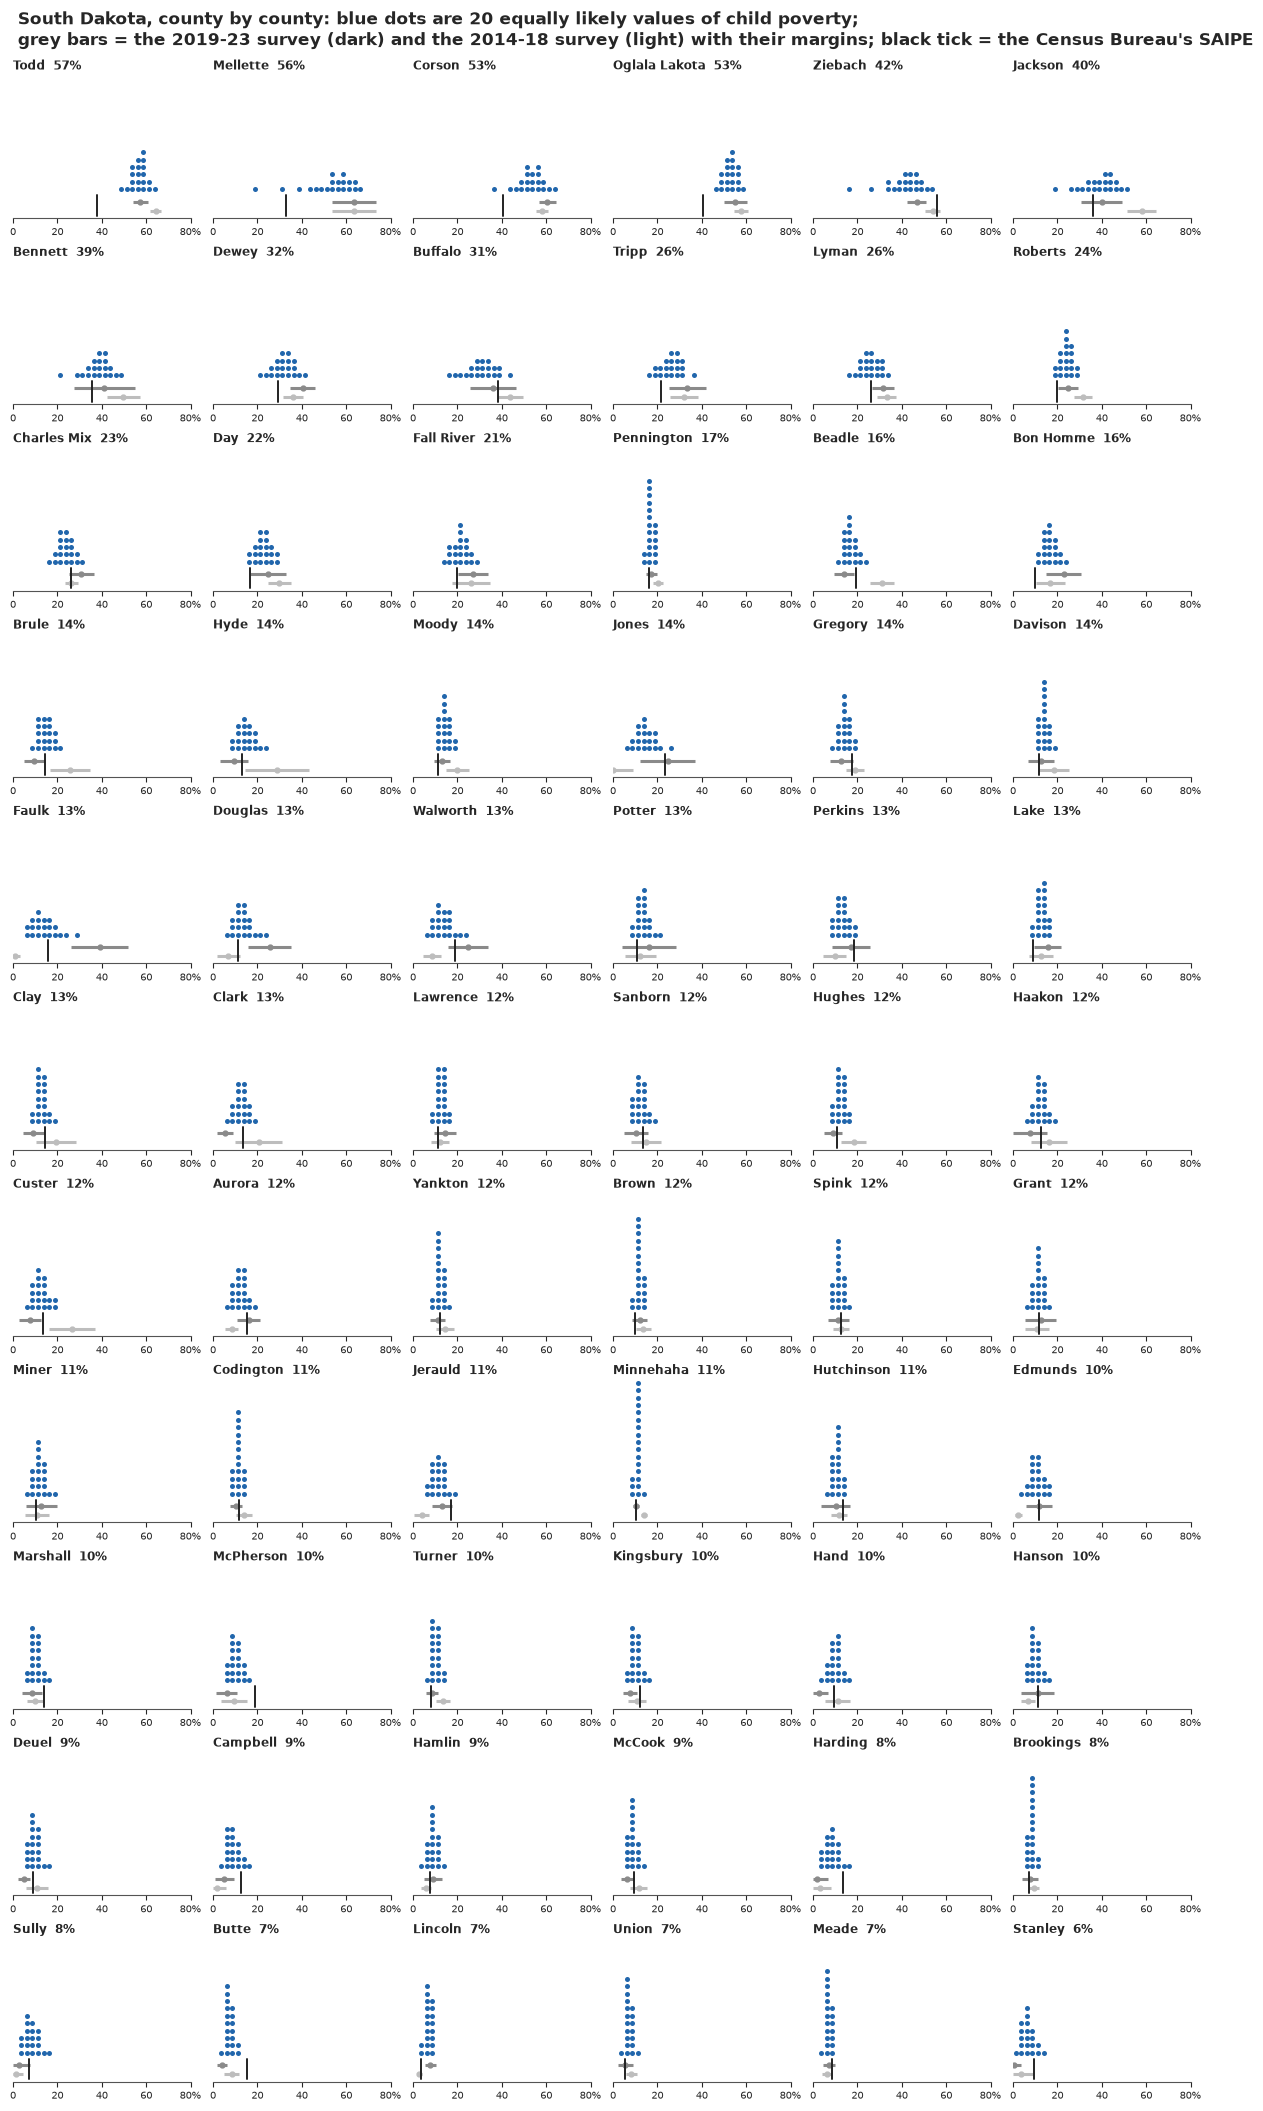

In [27]:
def dot_stack(i, n=20, w=0.025):
    """x and stack height of the n quantile dots of county i, in bins of width w."""
    col = np.floor(np.quantile(PI_2[i], (np.arange(n) + 0.5) / n) / w).astype(int)
    hgt = np.array([(col[:k + 1] == c_).sum() for k, c_ in enumerate(col)])
    return (col + 0.5) * w, hgt


def card(ax, i, top, xmax=0.8):
    xs, ys = dot_stack(i)
    ax.scatter(xs, ys, s=13, color=HI, lw=0, zorder=3)
    for p_, se_, y_, col in [(P[i], SE[i], -0.7, MUTED), (P18[i], SE18[i], -1.9, "#bdbdbd")]:
        if y_ < -1 and not OK18[i]:
            continue
        ax.plot([max(p_ - 1.645 * se_, 0), p_ + 1.645 * se_], [y_, y_], color=col, lw=2.2,
                solid_capstyle="butt")
        ax.plot([p_], [y_], "o", color=col, ms=3.5)
    if not np.isnan(SAIPE[i]):
        ax.plot([SAIPE[i]] * 2, [-2.6, 0.2], color=INK, lw=1.4)
    ax.set(xlim=(0, xmax), ylim=(-2.9, top + 0.8), yticks=[])
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8], ["0", "20", "40", "60", "80%"], fontsize=7)
    for s_ in ("left", "right", "top"):
        ax.spines[s_].set_visible(False)
    ax.set_title(f"{D['county'][i].replace(' County', '')}  {p_2[i]:.0%}", fontsize=8.5, loc="left",
                 pad=1)


sd_rows = np.flatnonzero(D["state"] == "SD")
sd_rows = sd_rows[np.argsort(-p_2[sd_rows])]
TOP = max(dot_stack(i)[1].max() for i in sd_rows)
fig, axes = plt.subplots(11, 6, figsize=(12, 21), layout="constrained")
for ax, i in zip(axes.ravel(), sd_rows):
    card(ax, i, TOP)
fig.suptitle("South Dakota, county by county: blue dots are 20 equally likely values of child "
             "poverty;\ngrey bars = the 2019-23 survey (dark) and the 2014-18 survey (light) with "
             "their margins; black tick = the Census Bureau's SAIPE", x=0.01, ha="left",
             fontsize=12.5)
print(f"tallest stack: {TOP} dots")
mz = sd_rows[:3]
print("highest three:", [(D["short"][i], f"{p_2[i]:.0%}") for i in mz])
smallest = D.loc[sd_rows].sort_values("n_children").iloc[0]
print("smallest SD county:", smallest["short"], int(smallest["n_children"]), "children");

The reservation counties at the top have stacks well above 40%, their surveys agree, and SAIPE
sits lower, at about 40%; Mellette's stack has a long left tail, the model's doubt about a survey
of 593 children. Further down, most stacks are narrow even where the grey survey bar is wide
(Jones, Potter): with a small survey the estimate leans on similar counties. Some cards show the
two surveys disagreeing: Faulk County's latest survey says 39%, its earlier one found almost no
poor children (4 of 505), and its stack sits around 13%, with SAIPE's tick. A reader can check a
county against both surveys and the Census Bureau's number without reading a table.

### Shrinkage, county by county

The idea of the whole notebook, that a small county's survey is pulled towards what similar
counties show, can be drawn directly. For Texas's 254 counties, a **beeswarm** of the surveys sits
above a beeswarm of our estimates, with dot size growing with the number of children and a line
joining the two positions of every county that moved more than 8 points.

Texas counties moved > 8 points: 35; median children among them 776


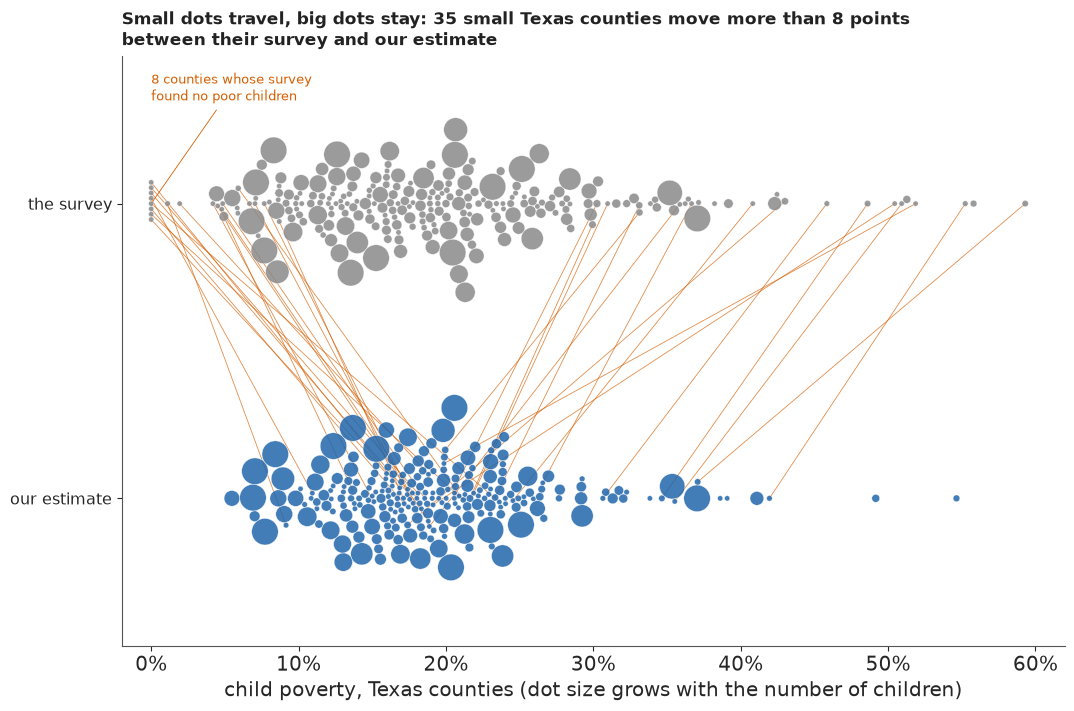

In [28]:
def beeswarm(x, r, y0):
    """Place dots of radii r (in x units) without overlap, each as close to y = y0 as it fits."""
    order = np.argsort(x)
    px, py, pr = [], [], []
    y = np.zeros_like(x)
    for i in order:
        cand = np.array([y0])
        if px:
            ax_, ay_, ar_ = np.array(px), np.array(py), np.array(pr)
            dmin = r[i] + ar_
            near = np.abs(x[i] - ax_) < dmin
            h = np.sqrt(np.maximum(dmin[near] ** 2 - (x[i] - ax_[near]) ** 2, 0)) + 1e-9
            cand = np.concatenate([cand, ay_[near] + h, ay_[near] - h])
            cand = cand[np.argsort(np.abs(cand - y0))]
            for c_ in cand:
                gap2 = (x[i] - ax_[near]) ** 2 + (c_ - ay_[near]) ** 2
                if np.all(gap2 >= dmin[near] ** 2 - 1e-12):
                    break
            cand = np.array([c_])
        y[i] = cand[0]
        px.append(x[i])
        py.append(y[i])
        pr.append(r[i])
    return y


tx = np.flatnonzero(D["state"] == "TX")
rad = np.clip(0.0026 * (N[tx] / np.median(N[tx])) ** 0.35, 0.0018, 0.009)  # grows with children
y_s = beeswarm(P[tx], rad, 0.10)
y_e = beeswarm(p_2[tx], rad, -0.10)
fig, ax = plt.subplots(figsize=(12, 7), layout="constrained")
for k, i in enumerate(tx):
    if abs(p_2[i] - P[i]) > 0.08:
        ax.plot([P[i], p_2[i]], [y_s[k], y_e[k]], color=LO, lw=0.6, alpha=0.7, zorder=1)
for yy, xx, col in [(y_s, P[tx], MUTED), (y_e, p_2[tx], HI)]:
    ax.add_collection(EllipseCollection(2 * rad, 2 * rad, 0, units="xy",
                                        offsets=np.column_stack([xx, yy]),
                                        offset_transform=ax.transData, facecolors=col,
                                        edgecolors="white", linewidths=0.3, alpha=0.85))
ax.set_aspect("equal")
ax.set(xlim=(-0.02, 0.62), ylim=(-0.2, 0.2), yticks=[0.10, -0.10])
ax.set_yticklabels(["the survey", "our estimate"], fontsize=11.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("child poverty, Texas counties (dot size grows with the number of children)")
n_zero_tx = int(ZERO[tx].sum())
ax.annotate(f"{n_zero_tx} counties whose survey\nfound no poor children", (0.0, 0.10),
            xytext=(0.0, 0.17), fontsize=9.5, color=LO, ha="left",
            arrowprops=dict(arrowstyle="-", lw=0.6, color=LO))
n_moved = int((np.abs(p_2[tx] - P[tx]) > 0.08).sum())
pub._title(ax, f"Small dots travel, big dots stay: {n_moved} small Texas counties move more than 8 "
           "points between their survey and our estimate")
print(f"Texas counties moved > 8 points: {n_moved}; median children among them "
      f"{np.median(N[tx][np.abs(p_2[tx] - P[tx]) > 0.08]):.0f}");

The big dots, Harris County, Dallas, San Antonio, the border cities, barely move. Small dots at
the left edge of the survey row, the zero counties among them, travel into the teens and
twenties; small dots at the right edge travel back. No maths is needed to see that a survey's size
decides how far to trust it.

### What the public version gains, and what it costs

Against the raw map, the estimates should remove the size artefact at the extremes, and the
surprise map adds a second question that does not shrink with size. We count the smallest fifth
among the 50 lowest and the 50 highest estimates, as in part A, and how much of the raw top 50
survives.

In [29]:
GP_POST = size_of_extremes(p_2)
print("estimates: of the 50 lowest, %d are in the smallest fifth (median %d children); "
      "of the 50 highest, %d (median %d)" % GP_POST)
print(f"top-50 overlap, raw survey against estimate: "
      f"{len(set(np.argsort(-P)[:50]) & set(np.argsort(-p_2)[:50]))} of 50")

estimates: of the 50 lowest, 3 are in the smallest fifth (median 26018 children); of the 50 highest, 16 (median 2717)
top-50 overlap, raw survey against estimate: 34 of 50


Of the 50 lowest estimates only 3 are in the smallest fifth, against 38 on the raw map. Ten would
be expected if size did not matter, so shrinkage now keeps small counties out of the low extreme
rather than putting them there. The top is steadier: 34 of the raw top 50 remain in the top 50.
Together the two maps separate "is this county poor?" from "is this county news?", which a
single map cannot, and against the caterpillar the cards and the VSUP colours put the uncertainty
into the picture people look at. The cost is that surprise is relative to a model set and a
threshold that nobody outside this notebook sees, and the public versions hide what a
statistician would most want told: published margins understate how often a small survey
misses. That is why the plain-words probability for Mason County comes with a confidence
statement: it is a model probability, and our trust in the model is *medium*.

In [30]:
MASON = IDX["48319"]
P_MASON = float((PI_2[MASON] > 0.10).mean())
HOW = (f"Mason County, Texas, whose latest survey found no poor children, comes out at "
       f"{p_2[MASON]:.0%} ({lo2[MASON]:.0%}-{hi2[MASON]:.0%}). "
       + pub.how_sure(P_MASON, "more than one child in ten there is poor", "medium",
                      "our outside check, the Census Bureau's estimates, shares part of our data "
                      f"and runs about {-SAIPE_TAB.loc['two surveys', 'bias q1']:.0f} points "
                      "higher in small counties"))
MOVE_SMALL = float(np.median(move[Q == 0]) * 100)
hi_surveys = 100 * np.concatenate([P[HIGH_ROWS], P18[HIGH_ROWS]])
hi_exp = 100 * EXP_PCT[HIGH_ROWS]
WHO_PLAIN = (", all on Dakota reservations or tribal land (Pine Ridge and Rosebud among them)"
             if N_NATIVE == N_HIGH and DAKOTAS else "")
NUM_WORD = dict(enumerate(["No", "One", "Two", "Three", "Four", "Five", "Six", "Seven", "Eight",
                           "Nine", "Ten"]))
LOW_PLAIN = (f"One, {D['short'][np.flatnonzero(S < -THRESH)[0]]}, is" if N_LOW == 1
             else f"{NUM_WORD.get(N_LOW, N_LOW)} are")
FOUND = ("Often not quite: a small county's single survey is easily several points off. Unless "
         "both surveys agree, the model pulls it towards similar counties, by about "
         f"{MOVE_SMALL:.0f} points in the smallest fifth of counties. "
         f"{NUM_WORD.get(N_HIGH, N_HIGH)} counties stand out as surprisingly poor{WHO_PLAIN}: "
         f"surveys there find {hi_surveys.min():.0f}-{hi_surveys.max():.0f}% of children poor, "
         f"against {hi_exp.min():.0f}-{hi_exp.max():.0f}% expected. {LOW_PLAIN} surprisingly "
         "low. How many stand out depends on settings; who leads does much less.")
PLAIN.update(Markdown(f"**What we found.** {FOUND}\n\n**How sure are we.** {HOW}"))
print(FOUND)
print(HOW)

Often not quite: a small county's single survey is easily several points off. Unless both surveys agree, the model pulls it towards similar counties, by about 4 points in the smallest fifth of counties. Seven counties stand out as surprisingly poor, all on Dakota reservations or tribal land (Pine Ridge and Rosebud among them): surveys there find 29-64% of children poor, against 10-14% expected. One, Los Alamos, NM, is surprisingly low. How many stand out depends on settings; who leads does much less.
Mason County, Texas, whose latest survey found no poor children, comes out at 18% (13%-25%). It is *very likely* (98%) that more than one child in ten there is poor. We have *medium confidence* in that figure: our outside check, the Census Bureau's estimates, shares part of our data and runs about 3 points higher in small counties.


In [31]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'classic': 6, 'one survey, normal errors': 12, 'one survey, t errors': 32, 'one survey, t errors and t effects': 34, 'marginal LOO': 34, 'two surveys': 84, 'total': 272}


## Summary

- **Fay-Herriot works, and the classic version is fast.** On the logit scale with the published
  margins it fits 3,142 counties in seconds, cuts the mean gap to SAIPE from about 4.0 to 3.2
  points, and trusts the local survey from a median 0.66 in the smallest fifth to 0.97 in the
  largest. Its good answer for the zero counties is an accident of the delta-method error.
- **A margin of error understates how often a small survey misses.** Two independent ACS samples
  disagree beyond three combined margins for 2.9% of counties, about eleven times what sampling
  error allows if real change is as small as in large counties, mostly in the smallest two
  fifths. Churn that scales like sampling variance explains little of it, and SAIPE sides with
  the recent survey barely half the time; other kinds of small-county change remain untested.
- **Failure 1: believing the zero.** A variance function tied to the true rate (Wolter; Liu et
  al.), with the published variances as chi-square data and normal errors, puts Mason County,
  Texas, whose survey found no poor children, at about 6%; SAIPE says 21%.
- **Failure 2: heavy tails from one survey explain away the poorest counties.** Student-t errors
  ($\nu_e \approx 3$) win marginal LOO and sample cleanly, yet move Corson County, South Dakota,
  from its surveyed 60% to under 20%; t county effects as well do not help.
- **Two surveys can tell a fluke from a fact.** With both samples, t errors and t county effects,
  the reservations keep their rates (Todd about 57%), Mason returns to about 18% (13-25%), the
  disagreement rate is roughly reproduced, a little high (3.5% replicated against 2.9% observed,
  at the edge of the range), and the mean gap to SAIPE falls to 2.7 points. Limits: it can trust
  the wrong survey (Tunica, Mississippi: 25% against SAIPE's 42%), it sits about 3 points below
  SAIPE in the smallest fifth, and it cannot see a bias shared by both ACS samples, which matters
  on the reservations, where SAIPE is 6-19 points lower.
- **Ranks are uncertain.** 17 counties are very likely among the 50 poorest for children; a small
  county's rank interval can run into the hundreds (Mellette, South Dakota).
- **For the public**: a surprise map that no longer follows county size, with 8 standouts (7
  higher, all Dakota counties with reservations or tribal land; Los Alamos lower), beside a VSUP
  map, county cards and a shrinkage beeswarm. The count runs from 0 to hundreds with the spreads;
  the leaders are steadier: 6-7 of the 8 are kept under two of four alternatives (doubled
  spreads, two expectations), 3 when the spreads are halved, none with a single small spread.

## Try it yourself

1. **Name the reservations.** Add an indicator for counties that hold most of an American Indian
   reservation (or the share of residents who are American Indian or Alaska Native, from ACS table
   B02001) to the regression part, refit the two-survey model, and redraw the surprise map. Which
   standouts remain, and what does it mean that a covariate can make a fact unsurprising?
2. **Borrow SAIPE's covariates.** SAIPE's strength is its tax and SNAP data. Use the 2014-18
   survey as a covariate in a one-survey model instead of as a second measurement, or add county
   SNAP participation if you can find it, and compare the agreement with SAIPE by size fifth. Does
   the 3-point gap in the smallest fifth close?
3. **A third survey.** The ACS 2009-2013 5-year sample is also independent of the other two. Add
   it with its own GVF and change term and see whether Tunica, Prentiss and Faulk counties, where
   two surveys disagree, get a tie-breaker, and how $\nu_e$ and $\nu$ change. A third period also
   lets the change variance grow for small counties, the assumption part D could only bound.